# Avance 4: Modelos Alternativos (PASTIS Dataset)

**Dataset:** PASTIS (Sentinel-2 / Sentinel-1 Satellite Time Series)  
**Marco de Trabajo:** Metodología CRISP-ML(Q) — Fase de Modeling

**Equipo: 13** · Entrega: 25 de octubre de 2026

---

## 📋 Tabla de Contenidos Metodológica

### 1. Configuración del Entorno y Carga de Datos
- Importación de librerías y parámetros del experimento
- Descarga selectiva del dataset desde Kaggle (compatible con Google Colab)
- Particiones oficiales (folds) y extracción de las 52 características del Avance 2/3
- Diagnóstico de los datos (correlación, asimetría, PCA) que motiva las decisiones de modelado

### 2. Construcción de Modelos Alternativos
- Selección de al menos 6 algoritmos individuales (no ensambles), de familias distintas
- Entrenamiento bajo las mismas particiones, características y métricas del baseline

### 3. Comparativa de Desempeño (60 pts)
- Tabla comparativa ordenada por la métrica principal (Macro F1), con Accuracy, Macro IoU, brecha de generalización, tamaño y tiempos
- Ranking multicriterio, F1 por clase y frente de Pareto desempeño–costo
- Intervalos de confianza por *bootstrap* a nivel de parche y comparaciones pareadas
- Selección de los dos mejores modelos

### 4. Ajuste Fino de los Dos Mejores Modelos (30 pts)
- Búsqueda aleatoria (modelo barato) y *successive halving* (modelo costoso), con validación cruzada agrupada por parche
- Espacios de búsqueda amplios: hiperparámetros, preprocesamiento, reducción de dimensión y *priors*
- Mejora medida con la misma validación cruzada, análisis de sensibilidad, significancia y curvas de aprendizaje

### 5. Elección del Modelo Individual Final (10 pts)
- Trade-offs entre métricas, tiempos, tamaño, interpretabilidad y complejidad; matriz de decisión con escenarios
- Evaluación única en el conjunto de prueba con intervalos de confianza, importancia de características y análisis de errores

### 6. Conclusiones Metodológicas CRISP-ML(Q)
- Resultados, limitaciones y líneas de trabajo para el siguiente avance

### Declaración de uso de herramientas de inteligencia artificial

## 1. Configuración del Entorno y Carga de Datos

Esta sección configura el entorno y prepara los datos reutilizando el procesamiento de los Avances 2 y 3: los mismos folds oficiales de PASTIS (entrenamiento = folds 1–3, validación = fold 4, prueba = fold 5) y las mismas **52 características espectrales y temporales por píxel** (13 variables × 4 estadísticas temporales).

Para que la libreta corra rápido en Google Colab **no se descarga el dataset completo (~27 GB)**: se descargan únicamente los metadatos y los parches necesarios. Si la descarga selectiva no estuviera disponible, el código recurre automáticamente a la descarga completa con `kagglehub.dataset_download`, como en el Avance 3.

A diferencia del Avance 3 (5 parches de validación y 5 de prueba), aquí se utilizan más parches por partición para que la comparación entre modelos sea menos sensible al azar. Los parámetros del experimento se controlan desde la celda 1.1.

In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO Y LIBRERÍAS
# ==============================================================================

# Librerías estándar de Python
import os
import io
import sys
import json
import time
import pickle
import platform
import threading
import warnings
from contextlib import redirect_stderr
from concurrent.futures import ThreadPoolExecutor

# Silenciar avisos también en los procesos paralelos de la búsqueda de hiperparámetros
os.environ["PYTHONWARNINGS"] = "ignore"
os.environ["KAGGLEHUB_VERBOSITY"] = "error"

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Procesamiento y seguimiento
from tqdm.auto import tqdm

# Estadística (distribuciones para la búsqueda de hiperparámetros)
import scipy
from scipy.stats import loguniform, randint, uniform, skew

# Machine Learning — modelos individuales (NO ensambles)
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, RobustScaler,
                                   PowerTransformer, QuantileTransformer)
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Random Forest: se usa ÚNICAMENTE como referencia del baseline (es un ensamble)
from sklearn.ensemble import RandomForestClassifier

# Selección de modelos y métricas
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 (habilita HalvingRandomSearchCV)
from sklearn.model_selection import (RandomizedSearchCV, HalvingRandomSearchCV,
                                     GroupKFold, cross_val_score)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    jaccard_score,
    classification_report,
    confusion_matrix,
    make_scorer
)

# Acceso a datasets
import kagglehub

# ------------------------------------------------------------------------------
# PARÁMETROS DEL EXPERIMENTO
# ------------------------------------------------------------------------------
MODO_RAPIDO = False   # True -> corrida reducida (menos parches y menos iteraciones) para pruebas

if MODO_RAPIDO:
    N_PARCHES = {"train": 40, "val": 10, "test": 10}
    N_ITER_ALEATORIA = 12          # configuraciones de la búsqueda aleatoria (modelos baratos)
    N_CANDIDATOS_HALVING = 18      # candidatos iniciales de successive halving (modelos costosos)
    MIN_RECURSOS_HALVING = 1_500   # muestras con las que se evalúa la primera ronda de halving
    MAX_MUESTRAS_SVM = 10_000
    MAX_MUESTRAS_BUSQUEDA = 15_000
    N_BOOTSTRAP = 300
else:
    N_PARCHES = {"train": 100, "val": 30, "test": 30}
    N_ITER_ALEATORIA = 60
    N_CANDIDATOS_HALVING = 72
    MIN_RECURSOS_HALVING = 3_000
    MAX_MUESTRAS_SVM = 20_000
    MAX_MUESTRAS_BUSQUEDA = 30_000
    N_BOOTSTRAP = 1_000

PIXELS_POR_PARCHE = 1000          # píxeles muestreados al azar por parche
CV_FOLDS = 3                      # folds de la validación cruzada del ajuste fino
DATASET_KAGGLE = "a01634782/pastis"
CLASES = list(range(20))
N_JOBS = -1

# Nombres de las clases semánticas de PASTIS (según la documentación del dataset)
NOMBRES_CLASES = {
    0: "Fondo", 1: "Pradera", 2: "Trigo blando de invierno", 3: "Maíz",
    4: "Cebada de invierno", 5: "Colza de invierno", 6: "Cebada de primavera",
    7: "Girasol", 8: "Vid", 9: "Remolacha", 10: "Triticale de invierno",
    11: "Trigo duro de invierno", 12: "Frutas, hortalizas y flores", 13: "Papa",
    14: "Forraje leguminoso", 15: "Soya", 16: "Huerto", 17: "Cereal mixto",
    18: "Sorgo", 19: "Etiqueta nula (void)",
}

# Reproducibilidad
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

# Configuración de visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Verificación de hardware y versiones (scikit-learn se ejecuta en CPU)
print("=== VERIFICACIÓN DEL ENTORNO ===")
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__,
      "| numpy:", np.__version__, "| pandas:", pd.__version__)
print("Núcleos de CPU disponibles:", os.cpu_count())
print("Modo rápido:", MODO_RAPIDO)
print("Parches por partición:", N_PARCHES)
print("Píxeles por parche:", PIXELS_POR_PARCHE)
print("Entorno configurado correctamente.")

=== VERIFICACIÓN DEL ENTORNO ===
Python: 3.13.16 | scikit-learn: 1.6.1 | numpy: 2.1.3 | pandas: 2.2.3
Núcleos de CPU disponibles: 2
Modo rápido: False
Parches por partición: {'train': 100, 'val': 30, 'test': 30}
Píxeles por parche: 1000
Entorno configurado correctamente.


In [2]:
# ==============================================================================
# 1.2 CARGA DEL DATASET PASTIS (DESCARGA SELECTIVA DESDE KAGGLE)
# ==============================================================================

USAR_DESCARGA_SELECTIVA = True


def descargar_archivo(ruta_relativa):
    """Descarga un único archivo del dataset sin bajar los ~27 GB completos."""
    return kagglehub.dataset_download(DATASET_KAGGLE, path=ruta_relativa)


print("=== DATASET PASTIS ===")
inicio = time.time()

try:
    metadata_path = descargar_archivo("PASTIS/metadata.geojson")
    dataset_path = None
    print("Modo de descarga: SELECTIVA (solo los parches necesarios)")

except Exception as error:
    print("Descarga selectiva no disponible:", repr(error)[:200])
    print("Modo de descarga: COMPLETA (puede tardar varios minutos)")
    USAR_DESCARGA_SELECTIVA = False
    dataset_path = kagglehub.dataset_download(DATASET_KAGGLE)
    metadata_path = os.path.join(dataset_path, "PASTIS", "metadata.geojson")


_candado_descarga = threading.Lock()


def activar_descarga_completa():
    """Plan B: si la descarga selectiva falla a mitad del proceso, baja el dataset completo."""
    global USAR_DESCARGA_SELECTIVA, dataset_path
    with _candado_descarga:
        if USAR_DESCARGA_SELECTIVA:
            print("\nLa descarga selectiva falló; se descarga el dataset completo (~27 GB)...")
            dataset_path = kagglehub.dataset_download(DATASET_KAGGLE)
            USAR_DESCARGA_SELECTIVA = False


def ruta_pastis(ruta_relativa):
    """Devuelve la ruta local de un archivo dentro de la carpeta PASTIS."""
    if USAR_DESCARGA_SELECTIVA:
        return descargar_archivo(f"PASTIS/{ruta_relativa}")
    return os.path.join(dataset_path, "PASTIS", ruta_relativa)


print("Metadatos:", metadata_path)
print(f"Tiempo: {time.time() - inicio:.1f} segundos")

=== DATASET PASTIS ===


100%|██████████| 7.04M/7.04M [00:00<00:00, 15.0MB/s]

Modo de descarga: SELECTIVA (solo los parches necesarios)
Metadatos: /root/.cache/kagglehub/datasets/a01634782/pastis/versions/1/PASTIS/metadata.geojson
Tiempo: 5.6 segundos


In [3]:
# ==============================================================================
# 1.3 METADATOS Y PARTICIONES OFICIALES
# ==============================================================================

# Cargar metadatos de PASTIS (GeoJSON -> DataFrame, no se requiere geometría)
with open(metadata_path, "r") as f:
    geojson = json.load(f)

metadata = pd.DataFrame([ft["properties"] for ft in geojson["features"]])

print("=== METADATOS PASTIS ===")
print("Número de registros:", len(metadata))
print("Columnas disponibles:", metadata.columns.tolist())

print("\nDistribución de folds:")
print(metadata["Fold"].value_counts().sort_index())

# Mismas particiones que el Avance 3
train_meta = metadata[metadata["Fold"].isin([1, 2, 3])].copy()
val_meta = metadata[metadata["Fold"] == 4].copy()
test_meta = metadata[metadata["Fold"] == 5].copy()

print("\n=== PARTICIONES ===")
print(f"Entrenamiento (folds 1-3): {len(train_meta):,} parches")
print(f"Validación    (fold 4):    {len(val_meta):,} parches")
print(f"Prueba        (fold 5):    {len(test_meta):,} parches")

# Verificar que no existan parches compartidos
ids_train = set(train_meta["ID_PATCH"].astype(int))
ids_val = set(val_meta["ID_PATCH"].astype(int))
ids_test = set(test_meta["ID_PATCH"].astype(int))

assert ids_train.isdisjoint(ids_val)
assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)

print("\nVerificación de separación: CORRECTA")

=== METADATOS PASTIS ===
Número de registros: 2433
Columnas disponibles: ['Fold', 'ID_PATCH', 'N_Parcel', 'Parcel_Cover', 'TILE', 'dates-S2', 'id']

Distribución de folds:
Fold
1    487
2    494
3    474
4    482
5    496
Name: count, dtype: int64

=== PARTICIONES ===
Entrenamiento (folds 1-3): 1,455 parches
Validación    (fold 4):    482 parches
Prueba        (fold 5):    496 parches

Verificación de separación: CORRECTA


In [4]:
# ==============================================================================
# 1.4 EXTRACCIÓN DE CARACTERÍSTICAS (MISMA FUNCIÓN DEL AVANCE 3)
# ==============================================================================

bandas_s2 = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
variables = bandas_s2 + ["NDVI", "NDWI", "EVI"]
estadisticas = ["media", "std", "min", "max"]

nombres_features = [
    f"{estadistica}_{variable}"
    for estadistica in estadisticas
    for variable in variables
]


def extraer_caracteristicas(imagen):
    """(T, 10, H, W) -> matriz (H*W, 52) con estadísticas temporales por píxel."""

    # Reescalamiento de reflectancia
    img = imagen.astype(np.float32) / 10000.0

    # Limitar reflectancias negativas
    img = np.maximum(img, 0.0)

    # Bandas espectrales
    azul = img[:, 0]
    verde = img[:, 1]
    rojo = img[:, 2]
    nir = img[:, 6]

    eps = 1e-4

    # Índices espectrales estabilizados
    ndvi = (nir - rojo) / np.maximum(nir + rojo, eps)
    ndwi = (verde - nir) / np.maximum(verde + nir, eps)

    denominador_evi = nir + 6 * rojo - 7.5 * azul + 1
    denominador_evi = np.where(
        denominador_evi >= 0,
        np.maximum(denominador_evi, eps),
        np.minimum(denominador_evi, -eps)
    )

    evi = np.clip(2.5 * (nir - rojo) / denominador_evi, -3, 3)

    # Integrar bandas e índices
    indices = np.stack([ndvi, ndwi, evi], axis=1)
    datos = np.concatenate([img, indices], axis=1)

    # Estadísticas temporales
    features = np.concatenate([
        np.mean(datos, axis=0),
        np.std(datos, axis=0),
        np.min(datos, axis=0),
        np.max(datos, axis=0)
    ], axis=0)

    return features.reshape(features.shape[0], -1).T


print("=== CARACTERÍSTICAS ===")
print("Número de características por píxel:", len(nombres_features))
print("Ejemplo:", nombres_features[:5], "...")

=== CARACTERÍSTICAS ===
Número de características por píxel: 52
Ejemplo: ['media_B2', 'media_B3', 'media_B4', 'media_B5', 'media_B6'] ...


In [5]:
# ==============================================================================
# 1.5 CONSTRUCCIÓN DE LOS CONJUNTOS DE ENTRENAMIENTO, VALIDACIÓN Y PRUEBA
# ==============================================================================

# Caché local: evita repetir la descarga y la extracción si se reinicia el entorno
CACHE = (
    "/content/pastis_avance4_cache.npz"
    if os.path.isdir("/content") else "pastis_avance4_cache.npz"
)
firma = f"{N_PARCHES}|{PIXELS_POR_PARCHE}|{SEED}"


def seleccionar_parches(df, cantidad, generador):
    ids = np.sort(df["ID_PATCH"].astype(int).to_numpy())
    elegidos = generador.choice(ids, size=min(cantidad, len(ids)), replace=False)
    return sorted(elegidos.tolist())


def preparar_parche(patch_id, intentos=4):
    """Carga un parche, extrae características y muestrea píxeles al azar."""
    for intento in range(intentos):
        try:
            img = np.load(ruta_pastis(f"DATA_S2/S2_{patch_id}.npy"))
            target = np.load(ruta_pastis(f"ANNOTATIONS/TARGET_{patch_id}.npy"))
            break
        except Exception:
            if intento == intentos - 1:
                raise
            if USAR_DESCARGA_SELECTIVA and intento >= 1:
                activar_descarga_completa()
            else:
                time.sleep(2)

    X = extraer_caracteristicas(img)
    y = target[0].reshape(-1)

    # Muestreo reproducible, independiente del orden de los hilos
    g = np.random.default_rng(SEED + int(patch_id))
    idx = g.choice(len(y), size=min(PIXELS_POR_PARCHE, len(y)), replace=False)

    return X[idx].astype(np.float32), y[idx].astype(np.int16)


def construir_conjunto(ids, nombre):
    # Las barras de descarga de kagglehub se escriben en stderr: se silencian para no
    # saturar la salida; la barra de avance propia se dirige a stdout.
    with redirect_stderr(io.StringIO()):
        with ThreadPoolExecutor(max_workers=6) as ejecutor:
            resultados = list(tqdm(
                ejecutor.map(preparar_parche, ids),
                total=len(ids), desc=nombre, file=sys.stdout
            ))

    X = np.vstack([r[0] for r in resultados])
    y = np.concatenate([r[1] for r in resultados])
    grupos = np.concatenate([
        np.full(len(r[1]), pid) for r, pid in zip(resultados, ids)
    ])
    return X, y, grupos


inicio = time.time()
usar_cache = False

if os.path.isfile(CACHE):
    with np.load(CACHE, allow_pickle=False) as z:
        if str(z["firma"]) == firma:
            datos = {k: z[k] for k in z.files if k != "firma"}
            usar_cache = True

if usar_cache:
    print("Datos recuperados de la caché local:", CACHE)
else:
    generador = np.random.default_rng(SEED)
    ids_elegidos = {
        "train": seleccionar_parches(train_meta, N_PARCHES["train"], generador),
        "val": seleccionar_parches(val_meta, N_PARCHES["val"], generador),
        "test": seleccionar_parches(test_meta, N_PARCHES["test"], generador),
    }

    datos = {}
    for nombre, etiqueta in [("train", "Entrenamiento"),
                             ("val", "Validación"),
                             ("test", "Prueba")]:
        X_, y_, g_ = construir_conjunto(ids_elegidos[nombre], etiqueta)
        datos[f"X_{nombre}"], datos[f"y_{nombre}"], datos[f"g_{nombre}"] = X_, y_, g_

    np.savez_compressed(CACHE, firma=np.array(firma), **datos)

X_train, y_train, g_train = datos["X_train"], datos["y_train"], datos["g_train"]
X_val, y_val, g_val = datos["X_val"], datos["y_val"], datos["g_val"]
X_test, y_test, g_test = datos["X_test"], datos["y_test"], datos["g_test"]

print("\n=== CONJUNTOS EXPERIMENTALES ===")
for nombre, X_, y_, g_ in [("Entrenamiento", X_train, y_train, g_train),
                           ("Validación", X_val, y_val, g_val),
                           ("Prueba", X_test, y_test, g_test)]:
    print(f"{nombre:14s} X={X_.shape}  parches={len(np.unique(g_)):3d}  "
          f"clases={len(np.unique(y_)):2d}")

print("\nValores finitos:",
      all(np.isfinite(X_).all() for X_ in (X_train, X_val, X_test)))
print(f"Tiempo total de preparación: {time.time() - inicio:.1f} segundos")

Entrenamiento:   0%|          | 0/100 [00:00<?, ?it/s]

Validación:   0%|          | 0/30 [00:00<?, ?it/s]

Prueba:   0%|          | 0/30 [00:00<?, ?it/s]


=== CONJUNTOS EXPERIMENTALES ===
Entrenamiento  X=(100000, 52)  parches=100  clases=20
Validación     X=(30000, 52)  parches= 30  clases=20
Prueba         X=(30000, 52)  parches= 30  clases=20

Valores finitos: True
Tiempo total de preparación: 178.0 segundos


=== DISTRIBUCIÓN DE CLASES (píxeles muestreados) ===


,Clase,Nombre,Entrenamiento,Validación,Prueba,% Entrenamiento
0,0,Fondo,41743,12517,11805,41.74
1,1,Pradera,19082,4803,5226,19.08
2,2,Trigo blando de invierno,6452,1796,2231,6.45
3,3,Maíz,9344,3123,2413,9.34
4,4,Cebada de invierno,1287,440,448,1.29
5,5,Colza de invierno,1234,145,622,1.23
6,6,Cebada de primavera,338,56,271,0.34
7,7,Girasol,656,223,392,0.66
8,8,Vid,2601,626,1523,2.60
9,9,Remolacha,977,440,73,0.98


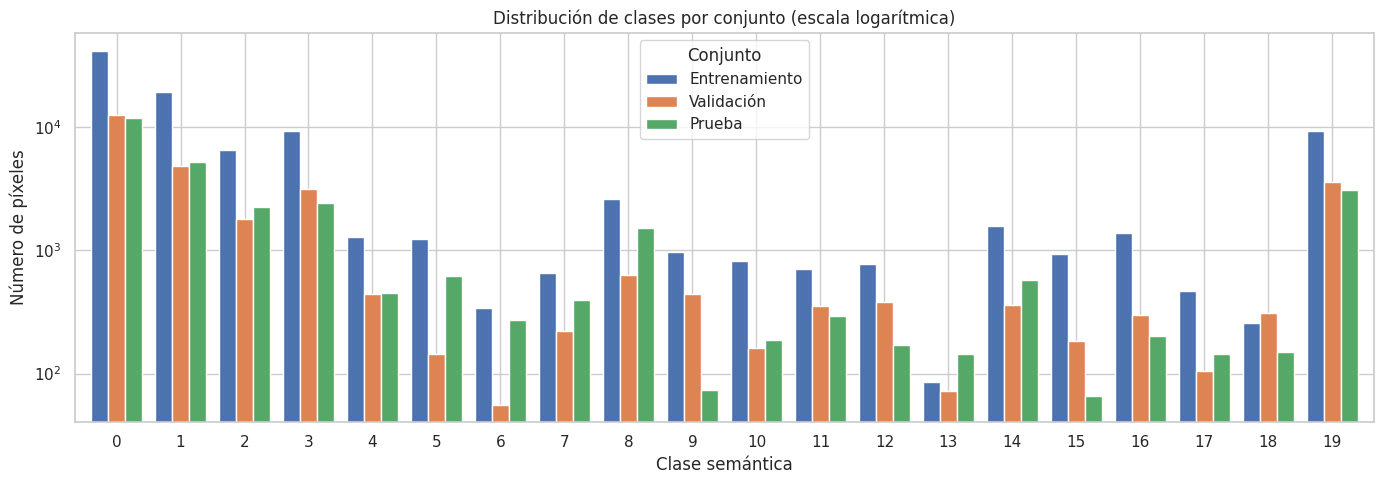

Clases ausentes en entrenamiento: []
Clases ausentes en validación: []
Clases ausentes en prueba: []
Razón de desbalance (clase mayoritaria / minoritaria) en entrenamiento: 491:1

Nota: las métricas macro se calculan sobre las clases presentes en cada conjunto evaluado.


In [6]:
# ==============================================================================
# 1.6 DISTRIBUCIÓN DE CLASES
# ==============================================================================

distribucion = pd.DataFrame({
    "Clase": CLASES,
    "Nombre": [NOMBRES_CLASES[c] for c in CLASES],
    "Entrenamiento": np.bincount(y_train.astype(int), minlength=20),
    "Validación": np.bincount(y_val.astype(int), minlength=20),
    "Prueba": np.bincount(y_test.astype(int), minlength=20),
})
distribucion["% Entrenamiento"] = (
    distribucion["Entrenamiento"] / len(y_train) * 100
).round(2)

print("=== DISTRIBUCIÓN DE CLASES (píxeles muestreados) ===")
display(distribucion)

ax = distribucion.set_index("Clase")[
    ["Entrenamiento", "Validación", "Prueba"]
].plot(kind="bar", figsize=(14, 5), width=0.8, logy=True)

plt.title("Distribución de clases por conjunto (escala logarítmica)")
plt.xlabel("Clase semántica")
plt.ylabel("Número de píxeles")
plt.xticks(rotation=0)
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()

ausentes_train = distribucion.loc[distribucion["Entrenamiento"] == 0, "Clase"].tolist()
ausentes_val = distribucion.loc[distribucion["Validación"] == 0, "Clase"].tolist()
ausentes_test = distribucion.loc[distribucion["Prueba"] == 0, "Clase"].tolist()

razon_desbalance = distribucion["Entrenamiento"].max() / distribucion["Entrenamiento"].min()
print("Clases ausentes en entrenamiento:", ausentes_train)
print("Clases ausentes en validación:", ausentes_val)
print("Clases ausentes en prueba:", ausentes_test)
print(f"Razón de desbalance (clase mayoritaria / minoritaria) en entrenamiento: {razon_desbalance:.0f}:1")
print("\nNota: las métricas macro se calculan sobre las clases presentes en cada conjunto evaluado.")

### 1.7 Diagnóstico de los datos que guía las decisiones de modelado

Antes de entrenar se revisan tres propiedades de las 52 características que condicionan qué algoritmos y qué preprocesamientos tienen sentido:

- **Correlación:** las estadísticas temporales de bandas vecinas están muy correlacionadas (multicolinealidad). Esto penaliza a los modelos lineales y probabilísticos sin regularización, y motiva probar *shrinkage* y PCA en el ajuste fino.
- **Asimetría:** si muchas características son muy asimétricas, transformaciones como Yeo-Johnson o cuantiles pueden ayudar a los modelos con supuestos gaussianos (LDA, Naive Bayes) y a las redes neuronales.
- **Dimensión efectiva (PCA):** indica cuánta información redundante hay y si una reducción de dimensión es razonable.

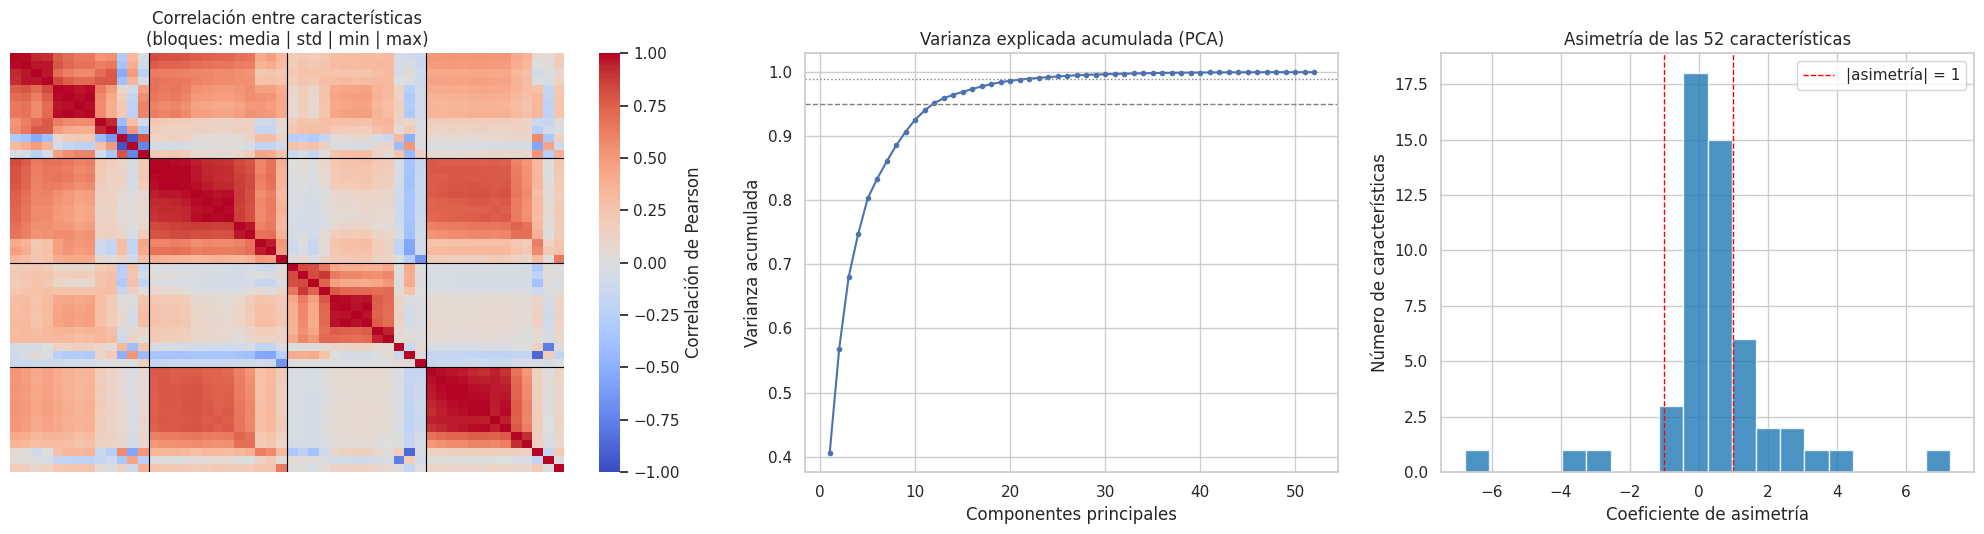

=== DIAGNÓSTICO DE LAS CARACTERÍSTICAS ===
Pares con |correlación| > 0.9: 80 de 1326 (6.0%)
Componentes PCA para explicar 95% / 99% de la varianza: 12 / 23 de 52
Características con |asimetría| > 1: 16 de 52



**Lectura.** 6% de los pares de características tienen |r| > 0.9 y bastan **12 componentes** para retener el 95% de la varianza:
hay redundancia considerable, por lo que la regularización (*shrinkage*, `alpha`) y la reducción de dimensión son hiperparámetros que vale la pena explorar.
16 características son marcadamente asimétricas, lo que justifica incluir transformaciones (Yeo-Johnson, cuantiles) en el espacio de búsqueda.


In [7]:
# ==============================================================================
# 1.7 DIAGNÓSTICO: CORRELACIÓN, ASIMETRÍA Y PCA
# ==============================================================================

idx_diag = np.random.default_rng(SEED).choice(len(X_train), size=min(20_000, len(X_train)), replace=False)
X_diag = X_train[idx_diag]

corr = np.corrcoef(X_diag, rowvar=False)
corr = np.nan_to_num(corr)

pca_diag = PCA(random_state=SEED).fit(StandardScaler().fit_transform(X_diag))
var_acum = np.cumsum(pca_diag.explained_variance_ratio_)
n_pca_95 = int(np.argmax(var_acum >= 0.95)) + 1
n_pca_99 = int(np.argmax(var_acum >= 0.99)) + 1

asimetria = skew(X_diag, axis=0)
n_asimetricas = int((np.abs(asimetria) > 1).sum())
pares_total = len(nombres_features) * (len(nombres_features) - 1) // 2
pares_altos = int((np.abs(np.triu(corr, 1)) > 0.9).sum())

fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})

sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ejes[0],
            xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Correlación de Pearson"})
for k in range(1, len(estadisticas)):
    ejes[0].axhline(13 * k, color="black", linewidth=0.8)
    ejes[0].axvline(13 * k, color="black", linewidth=0.8)
ejes[0].set_title("Correlación entre características\n(bloques: media | std | min | max)")

ejes[1].plot(range(1, len(var_acum) + 1), var_acum, marker="o", markersize=3)
ejes[1].axhline(0.95, color="gray", linestyle="--", linewidth=1)
ejes[1].axhline(0.99, color="gray", linestyle=":", linewidth=1)
ejes[1].set_title("Varianza explicada acumulada (PCA)")
ejes[1].set_xlabel("Componentes principales")
ejes[1].set_ylabel("Varianza acumulada")

ejes[2].hist(asimetria, bins=20, color="tab:blue", alpha=0.8)
ejes[2].axvline(-1, color="red", linestyle="--", linewidth=1)
ejes[2].axvline(1, color="red", linestyle="--", linewidth=1, label="|asimetría| = 1")
ejes[2].set_title("Asimetría de las 52 características")
ejes[2].set_xlabel("Coeficiente de asimetría")
ejes[2].set_ylabel("Número de características")
ejes[2].legend()

plt.tight_layout()
plt.show()

print("=== DIAGNÓSTICO DE LAS CARACTERÍSTICAS ===")
print(f"Pares con |correlación| > 0.9: {pares_altos} de {pares_total} ({pares_altos / pares_total:.1%})")
print(f"Componentes PCA para explicar 95% / 99% de la varianza: {n_pca_95} / {n_pca_99} de {X_diag.shape[1]}")
print(f"Características con |asimetría| > 1: {n_asimetricas} de {X_diag.shape[1]}")

hay_redundancia = pares_altos / pares_total >= 0.05 or n_pca_95 <= 0.6 * X_diag.shape[1]
frase_redundancia = (
    "hay redundancia considerable, por lo que la regularización (*shrinkage*, `alpha`) y la reducción de dimensión son hiperparámetros que vale la pena explorar."
    if hay_redundancia else
    "la redundancia es moderada; aun así, la regularización y la reducción de dimensión se mantienen como hiperparámetros a explorar."
)
frase_asimetria = (
    "lo que justifica incluir transformaciones (Yeo-Johnson, cuantiles) en el espacio de búsqueda."
    if n_asimetricas >= 5 else
    "por lo que las transformaciones (Yeo-Johnson, cuantiles) se incluyen en el espacio de búsqueda como alternativa, sin suponer que serán necesarias."
)

display(Markdown(f"""
**Lectura.** {pares_altos / pares_total:.0%} de los pares de características tienen |r| > 0.9 y bastan **{n_pca_95} componentes** para retener el 95% de la varianza:
{frase_redundancia}
{n_asimetricas} características son marcadamente asimétricas, {frase_asimetria}
"""))

## 2. Construcción de Modelos Alternativos

El baseline del Avance 3 fue un Random Forest, que es un **ensamble**. Como este avance pide modelos **individuales**, el Random Forest no participa en la comparación: únicamente se reentrena al final como referencia sobre los mismos datos.

Se construyen **7 modelos de familias distintas**, todos entrenados con las mismas 52 características y las mismas particiones:

| Modelo | Familia | Motivo de inclusión |
|---|---|---|
| Regresión Logística | Lineal | Referencia simple e interpretable (coeficientes por clase) |
| K-Vecinos más Cercanos | Basado en instancias | Captura fronteras no lineales sin entrenamiento explícito |
| Árbol de Decisión | Árbol individual | Interpretable; permite comparar un árbol contra su ensamble (Random Forest) |
| Naive Bayes Gaussiano | Probabilístico | Muy rápido; supone independencia entre características |
| Análisis Discriminante Lineal | Estadístico | Fronteras lineales con covarianza compartida |
| SVM (kernel RBF) | Kernel | Fronteras no lineales; costoso, por lo que se entrena con una submuestra |
| Red Neuronal (MLP) | Redes neuronales | Alta capacidad; hiperparámetros como arquitectura, activación y tasa de aprendizaje |

**Métrica principal:** Macro F1, igual que en el Avance 3, porque el dataset está fuertemente desbalanceado y Accuracy favorece a las clases mayoritarias. Se reportan además Accuracy, Macro IoU, la brecha de generalización (Macro F1 en entrenamiento menos validación), el tamaño del modelo y los tiempos de entrenamiento y predicción.

**Estructura común.** Todos los modelos se implementan como `Pipeline` con tres pasos (`scaler` → `reductor` → `clf`). El reductor es `passthrough` en la configuración inicial y queda disponible como hiperparámetro en el ajuste fino.

Los modelos se comparan y se ajustan usando únicamente **entrenamiento y validación**. El conjunto de **prueba** se reserva para evaluar una sola vez el modelo final.

In [8]:
# ==============================================================================
# 2.1 FUNCIONES DE EVALUACIÓN Y DEFINICIÓN DE MODELOS
# ==============================================================================

def metricas(y_real, y_pred):
    """Accuracy, Macro F1 y Macro IoU sobre las clases presentes en y_real."""
    clases_presentes = np.unique(y_real)
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Macro F1": f1_score(y_real, y_pred, labels=clases_presentes,
                             average="macro", zero_division=0),
        "Macro IoU": jaccard_score(y_real, y_pred, labels=clases_presentes,
                                   average="macro", zero_division=0),
    }


def f1_macro_presentes(y_real, y_pred):
    return f1_score(y_real, y_pred, labels=np.unique(y_real),
                    average="macro", zero_division=0)


scorer_f1 = make_scorer(f1_macro_presentes)


class LDAPriorsAjustables(LinearDiscriminantAnalysis):
    """LDA cuyos *priors* de clase se interpolan entre uniformes y frecuencias reales.

    prior_k ∝ (n_k) ** potencia_priors
      - potencia_priors = 1.0 -> frecuencias reales (comportamiento estándar de LDA)
      - potencia_priors = 0.0 -> priors uniformes (favorece el recall de clases raras)
    Es un hiperparámetro continuo que permite explorar el compromiso Accuracy / Macro F1.
    """

    def __init__(self, solver="svd", shrinkage=None, tol=1e-4, potencia_priors=1.0):
        super().__init__(solver=solver, shrinkage=shrinkage, tol=tol)
        self.potencia_priors = potencia_priors

    def fit(self, X, y):
        _, conteos = np.unique(y, return_counts=True)
        pesos = conteos.astype(float) ** self.potencia_priors
        self.priors = pesos / pesos.sum()
        return super().fit(X, y)


def crear_pipeline(clasificador):
    """Estructura común: escalado -> (reductor opcional) -> clasificador."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("reductor", "passthrough"),
        ("clf", clasificador),
    ])


def crear_modelos(n_jobs=-1):
    """Configuración inicial (por defecto) de los 7 modelos individuales."""
    return {
        "Regresión Logística": crear_pipeline(
            LogisticRegression(C=1.0, max_iter=300, class_weight="balanced")),
        "K-Vecinos más Cercanos": crear_pipeline(
            KNeighborsClassifier(n_neighbors=15, n_jobs=n_jobs)),
        "Árbol de Decisión": crear_pipeline(
            DecisionTreeClassifier(max_depth=12, min_samples_leaf=5,
                                   class_weight="balanced", random_state=SEED)),
        "Naive Bayes Gaussiano": crear_pipeline(GaussianNB()),
        "Análisis Discriminante Lineal": crear_pipeline(LDAPriorsAjustables()),
        "SVM (kernel RBF)": crear_pipeline(
            SVC(kernel="rbf", C=1.0, gamma="scale",
                class_weight="balanced", cache_size=1000)),
        "Red Neuronal (MLP)": crear_pipeline(
            MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu",
                          alpha=1e-4, learning_rate_init=1e-3, batch_size=256,
                          early_stopping=True, n_iter_no_change=8,
                          max_iter=100, random_state=SEED)),
    }


# Submuestras fijas (reproducibles)
rng_sub = np.random.default_rng(SEED)
idx_eval_train = rng_sub.choice(len(X_train), size=min(10_000, len(X_train)), replace=False)
idx_svm = rng_sub.choice(len(X_train), size=min(MAX_MUESTRAS_SVM, len(X_train)), replace=False)

# Número máximo de muestras de entrenamiento por modelo (SVM tiene costo ~O(n²))
SUBMUESTRA = {"SVM (kernel RBF)": idx_svm}


def datos_entrenamiento(nombre):
    idx = SUBMUESTRA.get(nombre)
    if idx is None:
        return X_train, y_train, g_train
    return X_train[idx], y_train[idx], g_train[idx]


def tamano_modelo_mb(modelo):
    """Tamaño aproximado del modelo serializado (MB): requisito de almacenamiento y despliegue."""
    return len(pickle.dumps(modelo, protocol=pickle.HIGHEST_PROTOCOL)) / 1e6


PRED_VAL = {}   # predicciones en validación de cada modelo (para IC bootstrap y F1 por clase)


def entrenar_y_evaluar(nombre, modelo, X_tr, y_tr, clave=None):
    """Entrena un modelo y mide métricas en validación, brecha de generalización, tamaño y tiempos."""
    t0 = time.time()
    modelo.fit(X_tr, y_tr)
    t_entrenamiento = time.time() - t0

    t0 = time.time()
    pred_val = modelo.predict(X_val)
    t_prediccion = time.time() - t0
    PRED_VAL[clave or nombre] = pred_val

    pred_tr = modelo.predict(X_train[idx_eval_train])
    m_val = metricas(y_val, pred_val)
    m_tr = metricas(y_train[idx_eval_train], pred_tr)

    return {
        "Modelo": nombre,
        "Muestras de entrenamiento": len(X_tr),
        "Accuracy": m_val["Accuracy"],
        "Macro F1": m_val["Macro F1"],
        "Macro IoU": m_val["Macro IoU"],
        "Macro F1 (entrenamiento)": m_tr["Macro F1"],
        "Brecha F1": m_tr["Macro F1"] - m_val["Macro F1"],
        "Tiempo entrenamiento (s)": t_entrenamiento,
        "Tiempo predicción (s)": t_prediccion,
        "Tamaño (MB)": tamano_modelo_mb(modelo),
    }


print("Modelos definidos:", list(crear_modelos().keys()))
print("Muestras de entrenamiento SVM:", len(idx_svm))

Modelos definidos: ['Regresión Logística', 'K-Vecinos más Cercanos', 'Árbol de Decisión', 'Naive Bayes Gaussiano', 'Análisis Discriminante Lineal', 'SVM (kernel RBF)', 'Red Neuronal (MLP)']
Muestras de entrenamiento SVM: 20000


In [9]:
# ==============================================================================
# 2.2 ENTRENAMIENTO DE LOS MODELOS ALTERNATIVOS
# ==============================================================================

modelos_base = crear_modelos()
modelos_entrenados = {}
registros = []

print("=== ENTRENAMIENTO DE MODELOS ALTERNATIVOS ===")

for nombre, modelo in tqdm(modelos_base.items(), desc="Modelos", file=sys.stdout):
    X_tr, y_tr, _ = datos_entrenamiento(nombre)
    resultado = entrenar_y_evaluar(nombre, modelo, X_tr, y_tr)

    modelos_entrenados[nombre] = modelo
    registros.append(resultado)

    print(f"{nombre:32s} Macro F1={resultado['Macro F1']:.4f}  "
          f"Acc={resultado['Accuracy']:.4f}  "
          f"entrenamiento={resultado['Tiempo entrenamiento (s)']:.1f}s")

df_resultados = (
    pd.DataFrame(registros)
    .sort_values("Macro F1", ascending=False)
    .set_index("Modelo")
)

# ------------------------------------------------------------------------------
# REFERENCIA: Random Forest del Avance 3 (ensamble; NO participa en la selección)
# ------------------------------------------------------------------------------
rf_referencia = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_split=10, min_samples_leaf=5,
    max_features="sqrt", class_weight="balanced_subsample",
    random_state=SEED, n_jobs=N_JOBS
)
fila_rf = entrenar_y_evaluar("Random Forest (referencia, ensamble)",
                             rf_referencia, X_train, y_train)

print(f"\n{'Random Forest (referencia)':32s} Macro F1={fila_rf['Macro F1']:.4f}  "
      f"Acc={fila_rf['Accuracy']:.4f}  "
      f"entrenamiento={fila_rf['Tiempo entrenamiento (s)']:.1f}s")

=== ENTRENAMIENTO DE MODELOS ALTERNATIVOS ===


Modelos:   0%|          | 0/7 [00:00<?, ?it/s]

Regresión Logística              Macro F1=0.2876  Acc=0.4051  entrenamiento=41.0s
K-Vecinos más Cercanos           Macro F1=0.1933  Acc=0.4929  entrenamiento=0.1s
Árbol de Decisión                Macro F1=0.1461  Acc=0.2915  entrenamiento=10.1s
Naive Bayes Gaussiano            Macro F1=0.1099  Acc=0.2012  entrenamiento=0.1s
Análisis Discriminante Lineal    Macro F1=0.3605  Acc=0.6094  entrenamiento=0.4s
SVM (kernel RBF)                 Macro F1=0.2550  Acc=0.4271  entrenamiento=55.3s
Red Neuronal (MLP)               Macro F1=0.2905  Acc=0.5779  entrenamiento=54.6s

Random Forest (referencia)       Macro F1=0.2312  Acc=0.4272  entrenamiento=62.3s


## 3. Comparativa de Desempeño

Se resumen en una sola tabla los siete modelos, ordenados por la métrica principal (**Macro F1** en validación). La tabla incluye Accuracy, Macro IoU, la brecha de generalización, el tamaño del modelo y los tiempos de entrenamiento y predicción. El Random Forest del Avance 3 aparece solo como línea de referencia.

Además de la tabla, la comparación se refuerza con: un **ranking multicriterio**, el **F1 por clase** de cada modelo, el **frente de Pareto** desempeño–costo y **intervalos de confianza por *bootstrap* a nivel de parche** para saber si las diferencias entre modelos son estadísticamente distinguibles.

=== COMPARATIVA DE MODELOS INDIVIDUALES (VALIDACIÓN) ===
Ordenados por Macro F1 (métrica principal)



,Macro F1,Accuracy,Macro IoU,Macro F1 (entrenamiento),Brecha F1,Tiempo entrenamiento (s),Tiempo predicción (s),Tamaño (MB),Muestras de entrenamiento
Modelo,,,,,,,,,
Análisis Discriminante Lineal,0.3605,0.6094,0.2487,0.4204,0.0599,0.4079,0.0228,0.0154,100000
Red Neuronal (MLP),0.2905,0.5779,0.1957,0.7601,0.4697,54.6140,0.0438,0.2070,100000
Regresión Logística,0.2876,0.4051,0.1874,0.3966,0.1090,40.9669,0.0211,0.0109,100000
SVM (kernel RBF),0.2550,0.4271,0.1626,0.4621,0.2071,55.3045,57.5459,10.2416,20000
K-Vecinos más Cercanos,0.1933,0.4929,0.1219,0.7159,0.5226,0.1024,18.4477,21.6024,100000
Árbol de Decisión,0.1461,0.2915,0.0859,0.4102,0.2640,10.0946,0.0131,0.7691,100000
Naive Bayes Gaussiano,0.1099,0.2012,0.0619,0.1328,0.0229,0.1332,0.1399,0.0192,100000



=== REFERENCIA: RANDOM FOREST DEL BASELINE (ENSAMBLE) ===


,Macro F1,Accuracy,Macro IoU,Macro F1 (entrenamiento),Brecha F1,Tiempo entrenamiento (s),Tiempo predicción (s),Tamaño (MB),Muestras de entrenamiento
Modelo,,,,,,,,,
"Random Forest (referencia, ensamble)",0.2312,0.4272,0.1443,0.6323,0.4011,62.2621,0.2634,75.4949,100000



=== RANKING MULTICRITERIO (1 = mejor) ===


,Rango Macro F1,Rango Accuracy,Rango Macro IoU,Rango brecha,Rango t. entrenamiento,Rango t. predicción,Rango promedio (desempeño),Rango promedio (todos)
Modelo,,,,,,,,
Análisis Discriminante Lineal,1.0,1.0,1.0,2.0,3.0,3.0,1.00,1.83
Regresión Logística,3.0,5.0,3.0,3.0,5.0,2.0,3.67,3.50
Red Neuronal (MLP),2.0,2.0,2.0,6.0,6.0,4.0,2.00,3.67
K-Vecinos más Cercanos,5.0,3.0,5.0,7.0,1.0,6.0,4.33,4.50
Árbol de Decisión,6.0,6.0,6.0,5.0,4.0,1.0,6.00,4.67
Naive Bayes Gaussiano,7.0,7.0,7.0,1.0,2.0,5.0,7.00,4.83
SVM (kernel RBF),4.0,4.0,4.0,4.0,7.0,7.0,4.00,5.00


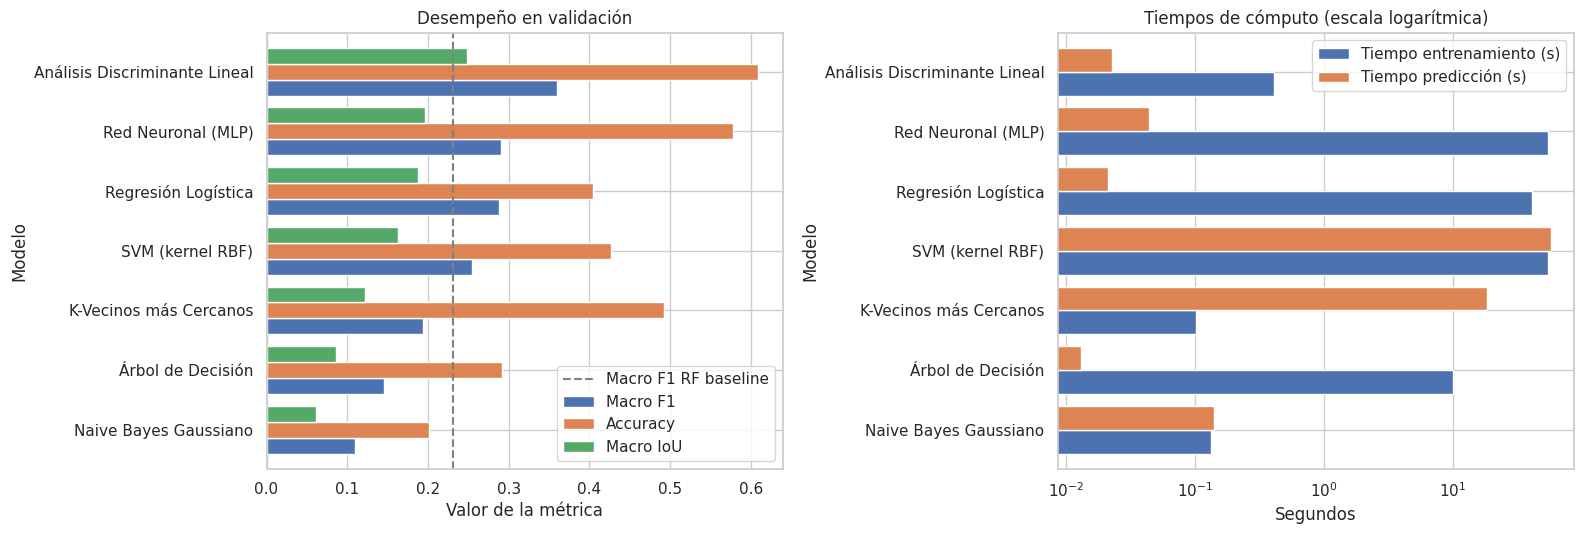

In [10]:
# ==============================================================================
# 3.1 TABLA COMPARATIVA DE MODELOS
# ==============================================================================

columnas_tabla = [
    "Macro F1", "Accuracy", "Macro IoU", "Macro F1 (entrenamiento)",
    "Brecha F1", "Tiempo entrenamiento (s)", "Tiempo predicción (s)",
    "Tamaño (MB)", "Muestras de entrenamiento"
]

print("=== COMPARATIVA DE MODELOS INDIVIDUALES (VALIDACIÓN) ===")
print("Ordenados por Macro F1 (métrica principal)\n")
display(df_resultados[columnas_tabla].round(4))

print("\n=== REFERENCIA: RANDOM FOREST DEL BASELINE (ENSAMBLE) ===")
display(pd.DataFrame([fila_rf]).set_index("Modelo")[columnas_tabla].round(4))

# Ranking multicriterio: posición en cada métrica (1 = mejor)
rangos = pd.concat([
    df_resultados[["Macro F1", "Accuracy", "Macro IoU"]].rank(ascending=False),
    df_resultados[["Brecha F1", "Tiempo entrenamiento (s)", "Tiempo predicción (s)"]].rank(ascending=True),
], axis=1)
rangos.columns = ["Rango Macro F1", "Rango Accuracy", "Rango Macro IoU",
                  "Rango brecha", "Rango t. entrenamiento", "Rango t. predicción"]
rangos["Rango promedio (desempeño)"] = rangos[["Rango Macro F1", "Rango Accuracy", "Rango Macro IoU"]].mean(axis=1)
rangos["Rango promedio (todos)"] = rangos.iloc[:, :6].mean(axis=1)

print("\n=== RANKING MULTICRITERIO (1 = mejor) ===")
display(rangos.sort_values("Rango promedio (todos)").round(2))

# Visualización: métricas y tiempos
fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))

(df_resultados[["Macro F1", "Accuracy", "Macro IoU"]]
 .iloc[::-1]
 .plot(kind="barh", ax=ejes[0], width=0.8))
ejes[0].axvline(fila_rf["Macro F1"], color="gray", linestyle="--",
                label="Macro F1 RF baseline")
ejes[0].set_title("Desempeño en validación")
ejes[0].set_xlabel("Valor de la métrica")
ejes[0].legend(loc="lower right")

(df_resultados[["Tiempo entrenamiento (s)", "Tiempo predicción (s)"]]
 .iloc[::-1]
 .plot(kind="barh", ax=ejes[1], width=0.8, logx=True))
ejes[1].set_title("Tiempos de cómputo (escala logarítmica)")
ejes[1].set_xlabel("Segundos")

plt.tight_layout()
plt.show()

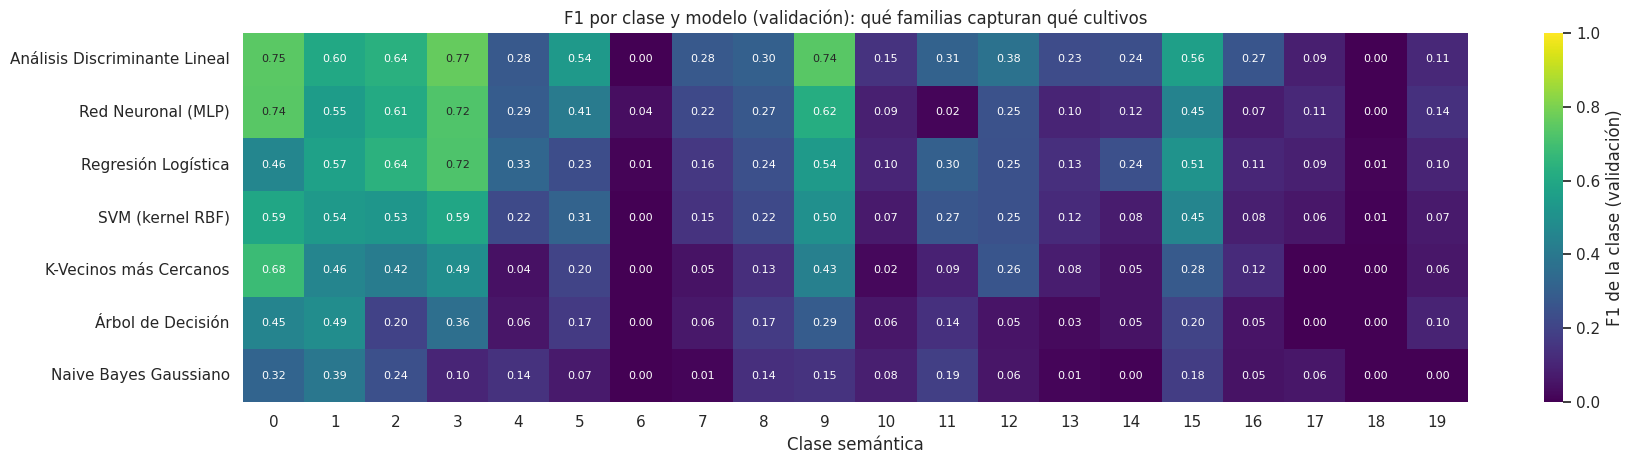

Modelo con mayor F1 en cada clase (número de clases ganadas):
Análisis Discriminante Lineal    13
Regresión Logística               4
Red Neuronal (MLP)                3


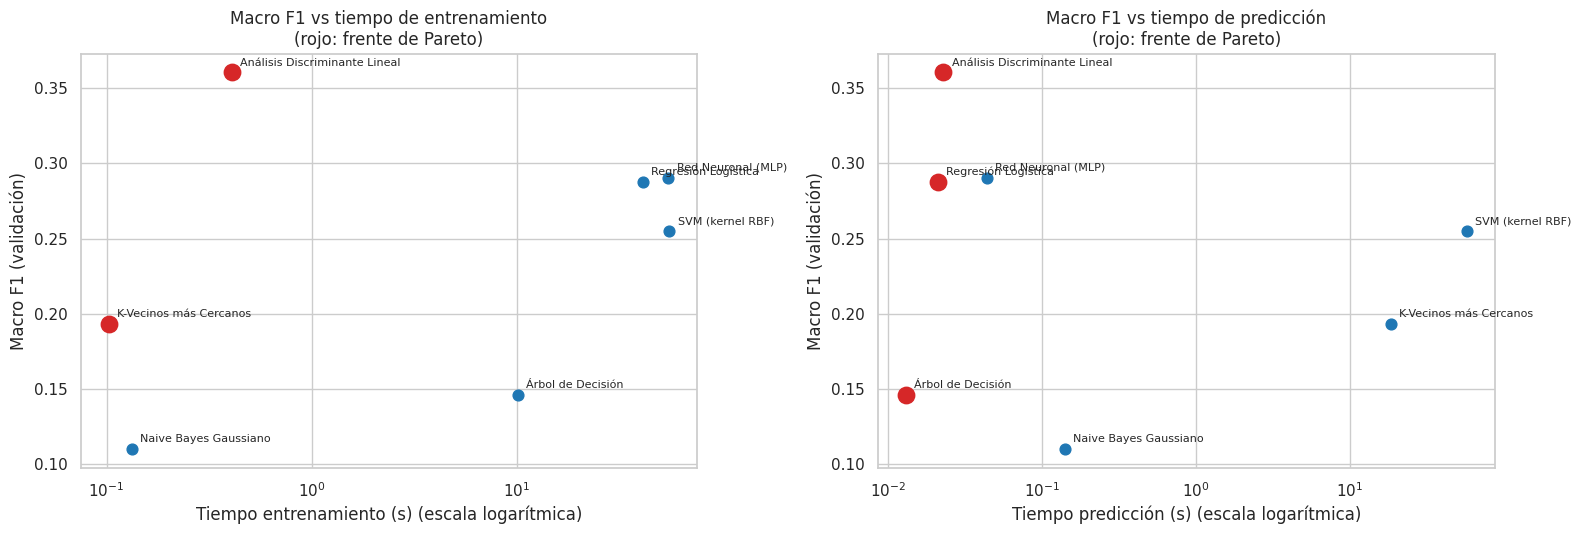

Modelos en el frente de Pareto (F1 vs tiempo de entrenamiento): ['Análisis Discriminante Lineal', 'K-Vecinos más Cercanos']
Modelos en el frente de Pareto (F1 vs tiempo de predicción): ['Análisis Discriminante Lineal', 'Regresión Logística', 'Árbol de Decisión']


In [11]:
# ==============================================================================
# 3.2 F1 POR CLASE Y FRENTE DE PARETO DESEMPEÑO–COSTO
# ==============================================================================

clases_val = np.unique(y_val)

f1_por_clase = pd.DataFrame(
    {nombre: f1_score(y_val, PRED_VAL[nombre], labels=clases_val, average=None, zero_division=0)
     for nombre in df_resultados.index},
    index=clases_val
).T

plt.figure(figsize=(18, 4.8))
sns.heatmap(f1_por_clase, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1,
            cbar_kws={"label": "F1 de la clase (validación)"}, annot_kws={"size": 8})
plt.title("F1 por clase y modelo (validación): qué familias capturan qué cultivos")
plt.xlabel("Clase semántica")
plt.ylabel("")
plt.tight_layout()
plt.show()

mejor_por_clase = f1_por_clase.idxmax()
conteo_mejor = mejor_por_clase.value_counts()
print("Modelo con mayor F1 en cada clase (número de clases ganadas):")
print(conteo_mejor.to_string())


def frente_pareto(df, col_costo, col_valor):
    """Marca los modelos no dominados: ninguno tiene menor costo y mayor valor a la vez."""
    pts = df[[col_costo, col_valor]].to_numpy()
    no_dominado = []
    for i, (c, v) in enumerate(pts):
        dominado = any(
            (pts[j, 0] <= c and pts[j, 1] >= v) and (pts[j, 0] < c or pts[j, 1] > v)
            for j in range(len(pts)) if j != i
        )
        no_dominado.append(not dominado)
    return np.array(no_dominado)


fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col_costo, titulo in [
    (ejes[0], "Tiempo entrenamiento (s)", "Macro F1 vs tiempo de entrenamiento"),
    (ejes[1], "Tiempo predicción (s)", "Macro F1 vs tiempo de predicción"),
]:
    pareto = frente_pareto(df_resultados, col_costo, "Macro F1")
    for (nombre, fila), en_frente in zip(df_resultados.iterrows(), pareto):
        ax.scatter(fila[col_costo], fila["Macro F1"], s=140 if en_frente else 60,
                   color="tab:red" if en_frente else "tab:blue", zorder=3)
        ax.annotate(nombre, (fila[col_costo], fila["Macro F1"]), textcoords="offset points",
                    xytext=(6, 5), fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel(col_costo + " (escala logarítmica)")
    ax.set_ylabel("Macro F1 (validación)")
    ax.set_title(titulo + "\n(rojo: frente de Pareto)")
plt.tight_layout()
plt.show()

print("Modelos en el frente de Pareto (F1 vs tiempo de entrenamiento):",
      df_resultados.index[frente_pareto(df_resultados, "Tiempo entrenamiento (s)", "Macro F1")].tolist())
print("Modelos en el frente de Pareto (F1 vs tiempo de predicción):",
      df_resultados.index[frente_pareto(df_resultados, "Tiempo predicción (s)", "Macro F1")].tolist())

### 3.3 Incertidumbre de la comparación: *bootstrap* por parche

La validación contiene pocos parches y los píxeles de un mismo parche están correlacionados. Por eso la incertidumbre se estima con un ***bootstrap* por conglomerados**: se remuestrean **parches completos** (con reemplazo) y se recalculan las métricas a partir de las matrices de confusión por parche. Los mismos remuestreos se usan para todos los modelos, lo que permite **comparaciones pareadas**: la probabilidad de que un modelo supere a otro en el remuestreo.

Antes de usar el procedimiento se verifica que reproduce exactamente las métricas de `scikit-learn`.

Verificación: las métricas por matriz de confusión coinciden con scikit-learn en los 7 modelos.

=== INTERVALOS DE CONFIANZA AL 95% (bootstrap de 1000 remuestreos de 30 parches) ===


,Macro F1,IC95% F1 inferior,IC95% F1 superior,Ancho IC,Accuracy IC95%,Macro IoU IC95%
Modelo,,,,,,
Análisis Discriminante Lineal,0.3605,0.2964,0.3936,0.0972,"[0.549, 0.669]","[0.201, 0.282]"
Red Neuronal (MLP),0.2905,0.2318,0.3229,0.0911,"[0.514, 0.638]","[0.153, 0.224]"
Regresión Logística,0.2876,0.2307,0.3243,0.0936,"[0.337, 0.474]","[0.144, 0.220]"
SVM (kernel RBF),0.2550,0.2033,0.2840,0.0807,"[0.355, 0.495]","[0.126, 0.188]"
K-Vecinos más Cercanos,0.1933,0.1529,0.2206,0.0677,"[0.432, 0.554]","[0.097, 0.142]"
Árbol de Decisión,0.1461,0.1188,0.1648,0.0461,"[0.243, 0.347]","[0.070, 0.099]"
Naive Bayes Gaussiano,0.1099,0.0808,0.1323,0.0515,"[0.144, 0.268]","[0.045, 0.076]"


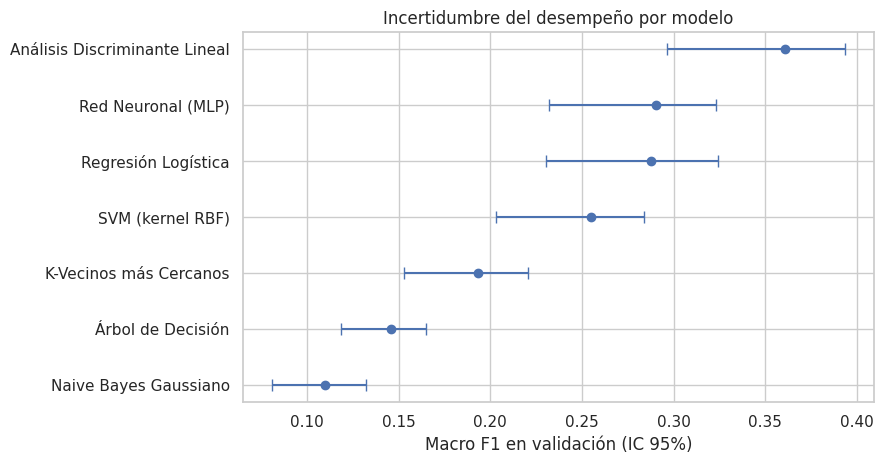


=== COMPARACIONES PAREADAS ENTRE MODELOS CONSECUTIVOS DEL RANKING ===


,Modelo superior,Modelo siguiente,Δ Macro F1,IC95% de Δ,P(superior)
0,Análisis Discriminante Lineal,Red Neuronal (MLP),0.070,"[0.040, 0.093]",1.000
1,Red Neuronal (MLP),Regresión Logística,0.003,"[-0.029, 0.032]",0.478
2,Regresión Logística,SVM (kernel RBF),0.033,"[0.005, 0.066]",0.994
3,SVM (kernel RBF),K-Vecinos más Cercanos,0.062,"[0.028, 0.090]",1.000
4,K-Vecinos más Cercanos,Árbol de Decisión,0.047,"[0.017, 0.068]",1.000
5,Árbol de Decisión,Naive Bayes Gaussiano,0.036,"[0.016, 0.056]",1.000


In [12]:
# ==============================================================================
# 3.3 BOOTSTRAP POR PARCHE: INTERVALOS DE CONFIANZA Y COMPARACIONES PAREADAS
# ==============================================================================

K = len(CLASES)


def matriz_por_parche(y_real, y_pred, grupos):
    """Matriz de confusión (K×K) de cada parche; la suma sobre parches es la matriz global."""
    ids, inv = np.unique(grupos, return_inverse=True)
    indice = inv.astype(np.int64) * K * K + y_real.astype(np.int64) * K + y_pred.astype(np.int64)
    return np.bincount(indice, minlength=len(ids) * K * K).reshape(len(ids), K, K)


def metricas_desde_matrices(M):
    """Accuracy, Macro F1 y Macro IoU desde matrices de confusión (filas = clase real).
    Admite una matriz (K×K) o un lote (n, K, K). Macro sobre clases con soporte > 0."""
    tp = np.diagonal(M, axis1=-2, axis2=-1).astype(float)
    soporte = M.sum(axis=-1)
    predichos = M.sum(axis=-2)
    presentes = soporte > 0
    f1 = 2 * tp / np.maximum(soporte + predichos, 1)
    iou = tp / np.maximum(soporte + predichos - tp, 1)
    n_presentes = presentes.sum(axis=-1)
    return {
        "Accuracy": tp.sum(axis=-1) / M.sum(axis=(-2, -1)),
        "Macro F1": (f1 * presentes).sum(axis=-1) / n_presentes,
        "Macro IoU": (iou * presentes).sum(axis=-1) / n_presentes,
    }


def indices_bootstrap(n_parches, n_boot, semilla):
    return np.random.default_rng(semilla).integers(0, n_parches, size=(n_boot, n_parches))


def bootstrap_metricas(mats, idx_boot):
    """Distribución bootstrap de las métricas (mismos remuestreos para todos los modelos)."""
    sumas = np.stack([mats[i].sum(axis=0) for i in idx_boot])
    return pd.DataFrame(metricas_desde_matrices(sumas))


def intervalo(serie, nivel=95):
    a = (100 - nivel) / 2
    return np.percentile(serie, a), np.percentile(serie, 100 - a)


mats_val = {n: matriz_por_parche(y_val, p, g_val) for n, p in PRED_VAL.items()}
n_parches_val = len(np.unique(g_val))
IDX_BOOT_VAL = indices_bootstrap(n_parches_val, N_BOOTSTRAP, SEED)
boot_val = {n: bootstrap_metricas(m, IDX_BOOT_VAL) for n, m in mats_val.items()}

# Verificación: la implementación vectorizada coincide con scikit-learn
for nombre in df_resultados.index:
    ref = metricas_desde_matrices(mats_val[nombre].sum(axis=0))
    for m in ["Accuracy", "Macro F1", "Macro IoU"]:
        assert np.isclose(ref[m], df_resultados.loc[nombre, m], atol=1e-9), (nombre, m)
print("Verificación: las métricas por matriz de confusión coinciden con scikit-learn en los 7 modelos.\n")

filas_ic = []
for nombre in df_resultados.index:
    fila = {"Modelo": nombre, "Macro F1": df_resultados.loc[nombre, "Macro F1"]}
    lo, hi = intervalo(boot_val[nombre]["Macro F1"])
    fila.update({"IC95% F1 inferior": lo, "IC95% F1 superior": hi, "Ancho IC": hi - lo})
    for m in ["Accuracy", "Macro IoU"]:
        lo_m, hi_m = intervalo(boot_val[nombre][m])
        fila[f"{m} IC95%"] = f"[{lo_m:.3f}, {hi_m:.3f}]"
    filas_ic.append(fila)
tabla_ic = pd.DataFrame(filas_ic).set_index("Modelo")

print(f"=== INTERVALOS DE CONFIANZA AL 95% (bootstrap de {N_BOOTSTRAP} remuestreos de {n_parches_val} parches) ===")
display(tabla_ic.round(4))

fig, ax = plt.subplots(figsize=(9, 4.8))
orden = tabla_ic.index[::-1]
ax.errorbar(tabla_ic.loc[orden, "Macro F1"], range(len(orden)),
            xerr=[tabla_ic.loc[orden, "Macro F1"] - tabla_ic.loc[orden, "IC95% F1 inferior"],
                  tabla_ic.loc[orden, "IC95% F1 superior"] - tabla_ic.loc[orden, "Macro F1"]],
            fmt="o", capsize=4)
ax.set_yticks(range(len(orden)))
ax.set_yticklabels(orden)
ax.set_xlabel("Macro F1 en validación (IC 95%)")
ax.set_title("Incertidumbre del desempeño por modelo")
plt.tight_layout()
plt.show()


def prob_superior(a, b, metrica="Macro F1"):
    """Probabilidad (bootstrap pareado) de que el modelo `a` supere al modelo `b`."""
    return float((boot_val[a][metrica] > boot_val[b][metrica]).mean())


ranking_f1 = df_resultados.index.tolist()
pares = []
for a, b in zip(ranking_f1[:-1], ranking_f1[1:]):
    d = boot_val[a]["Macro F1"] - boot_val[b]["Macro F1"]
    lo, hi = intervalo(d)
    pares.append({"Modelo superior": a, "Modelo siguiente": b,
                  "Δ Macro F1": df_resultados.loc[a, "Macro F1"] - df_resultados.loc[b, "Macro F1"],
                  "IC95% de Δ": f"[{lo:.3f}, {hi:.3f}]",
                  "P(superior)": prob_superior(a, b)})
print("\n=== COMPARACIONES PAREADAS ENTRE MODELOS CONSECUTIVOS DEL RANKING ===")
display(pd.DataFrame(pares).round(3))

In [13]:
# ==============================================================================
# 3.4 SELECCIÓN DE LOS DOS MEJORES MODELOS
# ==============================================================================

top2 = df_resultados.head(2).index.tolist()

print("=== MODELOS SELECCIONADOS PARA AJUSTE FINO ===")
for posicion, nombre in enumerate(top2, start=1):
    fila = df_resultados.loc[nombre]
    print(f"{posicion}. {nombre}: Macro F1={fila['Macro F1']:.4f} | "
          f"Accuracy={fila['Accuracy']:.4f} | Macro IoU={fila['Macro IoU']:.4f} | "
          f"brecha F1={fila['Brecha F1']:.3f} | "
          f"entrenamiento={fila['Tiempo entrenamiento (s)']:.1f}s")

mejor = df_resultados.iloc[0]
tercero = df_resultados.iloc[2]
dif_2_3 = df_resultados.iloc[1]["Macro F1"] - tercero["Macro F1"]
p_2_sobre_3 = prob_superior(top2[1], df_resultados.index[2])
p_1_sobre_2 = prob_superior(top2[0], top2[1])

display(Markdown(f"""
**Criterio de selección.** Se eligen los dos modelos con mayor Macro F1 en validación.
La diferencia entre el segundo y el tercer lugar es de **{dif_2_3:.4f}** puntos de Macro F1
(probabilidad bootstrap de que el segundo supere al tercero: **{p_2_sobre_3:.0%}**),
por lo que el corte entre modelos seleccionados y descartados {'es amplio' if dif_2_3 > 0.02 else 'es estrecho y debe interpretarse con cautela'}.
La probabilidad de que **{top2[0]}** supere a **{top2[1]}** es de **{p_1_sobre_2:.0%}**.

**Contexto frente al baseline.** El Random Forest de referencia obtiene Macro F1 = **{fila_rf['Macro F1']:.4f}** en estos mismos datos;
el mejor modelo individual obtiene **{mejor['Macro F1']:.4f}** ({mejor['Macro F1'] - fila_rf['Macro F1']:+.4f}).
"""))

=== MODELOS SELECCIONADOS PARA AJUSTE FINO ===
1. Análisis Discriminante Lineal: Macro F1=0.3605 | Accuracy=0.6094 | Macro IoU=0.2487 | brecha F1=0.060 | entrenamiento=0.4s
2. Red Neuronal (MLP): Macro F1=0.2905 | Accuracy=0.5779 | Macro IoU=0.1957 | brecha F1=0.470 | entrenamiento=54.6s



**Criterio de selección.** Se eligen los dos modelos con mayor Macro F1 en validación.
La diferencia entre el segundo y el tercer lugar es de **0.0029** puntos de Macro F1
(probabilidad bootstrap de que el segundo supere al tercero: **48%**),
por lo que el corte entre modelos seleccionados y descartados es estrecho y debe interpretarse con cautela.
La probabilidad de que **Análisis Discriminante Lineal** supere a **Red Neuronal (MLP)** es de **100%**.

**Contexto frente al baseline.** El Random Forest de referencia obtiene Macro F1 = **0.2312** en estos mismos datos;
el mejor modelo individual obtiene **0.3605** (+0.1292).


## 4. Ajuste Fino de los Dos Mejores Modelos

El ajuste de hiperparámetros se diseña según el **costo de cada modelo**, y en ambos casos se explora un espacio amplio:

- **Búsqueda aleatoria (`RandomizedSearchCV`)** para modelos baratos de entrenar (p. ej. LDA): permite evaluar decenas de configuraciones completas.
- **Successive halving (`HalvingRandomSearchCV`)** para modelos costosos (p. ej. red neuronal, SVM): se evalúan muchos candidatos con pocos datos y solo los mejores pasan a rondas con más datos. Así se cubre un espacio mucho mayor con el mismo presupuesto de cómputo.

Decisiones metodológicas:

- **Validación cruzada agrupada por parche (`GroupKFold`).** Los píxeles de un mismo parche son vecinos y muy parecidos entre sí. Si se mezclaran píxeles del mismo parche entre los folds de entrenamiento y validación, la métrica sería optimista y se elegirían hiperparámetros que sobreajustan.
- **Métrica de optimización:** Macro F1 (la misma métrica principal).
- **La configuración inicial se evalúa con la misma validación cruzada** que la mejor configuración encontrada, de modo que la mejora se mide en igualdad de condiciones y no solo en un único fold de validación.
- **Espacios de búsqueda amplios.** Incluyen regularización, ponderación de clases, preprocesamiento (escalado, Yeo-Johnson, cuantiles), reducción de dimensión (PCA), *priors* de clase (LDA) y, para la red neuronal, arquitectura, función de activación, tasa de aprendizaje, tamaño de lote, regularización L2 y paciencia del *early stopping*.
- El conjunto de validación (fold 4) **no se usa dentro de la búsqueda**: sirve para confirmar si la mejora generaliza.

In [14]:
# ==============================================================================
# 4.1 ESPACIOS DE BÚSQUEDA DE HIPERPARÁMETROS
# ==============================================================================

# Alternativas de preprocesamiento y reducción de dimensión (pasos "scaler" y "reductor")
ESCALADORES = [
    StandardScaler(),
    RobustScaler(),
    PowerTransformer(method="yeo-johnson"),
    QuantileTransformer(n_quantiles=200, output_distribution="normal",
                        subsample=100_000, random_state=SEED),
]
REDUCTORES = [
    "passthrough",
    PCA(n_components=0.99, random_state=SEED),
    PCA(n_components=0.95, random_state=SEED),
]

# Hiperparámetros comunes de LDA (preprocesamiento y priors)
LDA_COMUN = {
    "scaler": ESCALADORES,
    "reductor": REDUCTORES,
    "clf__potencia_priors": uniform(0.0, 1.0),    # 0 = priors uniformes, 1 = frecuencias reales
}

ESPACIOS = {
    "Regresión Logística": {
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": [None, "balanced"],
        "scaler": ESCALADORES,
    },
    "K-Vecinos más Cercanos": {
        "clf__n_neighbors": randint(3, 60),
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2],
        "scaler": ESCALADORES,
        "reductor": REDUCTORES,
    },
    "Árbol de Decisión": {
        "clf__max_depth": randint(4, 30),
        "clf__min_samples_leaf": randint(1, 60),
        "clf__min_samples_split": randint(2, 60),
        "clf__criterion": ["gini", "entropy"],
        "clf__class_weight": [None, "balanced"],
        "clf__ccp_alpha": loguniform(1e-6, 1e-3),
    },
    "Naive Bayes Gaussiano": {
        "clf__var_smoothing": loguniform(1e-11, 1e-1),
        "scaler": ESCALADORES,
        "reductor": REDUCTORES,
    },
    "Análisis Discriminante Lineal": [
        {**LDA_COMUN, "clf__solver": ["svd"], "clf__tol": loguniform(1e-6, 1e-2)},
        {**LDA_COMUN, "clf__solver": ["lsqr"], "clf__shrinkage": ["auto"]},
        {**LDA_COMUN, "clf__solver": ["lsqr"], "clf__shrinkage": uniform(0.0, 1.0)},
    ],
    "SVM (kernel RBF)": {
        "clf__C": loguniform(0.1, 200),
        "clf__gamma": loguniform(1e-3, 1),
        "clf__class_weight": [None, "balanced"],
        "scaler": ESCALADORES,
    },
    "Red Neuronal (MLP)": {
        "clf__hidden_layer_sizes": [(32,), (64,), (128,), (256,), (64, 32), (128, 64),
                                    (256, 128), (128, 64, 32), (256, 128, 64)],
        "clf__activation": ["relu", "tanh"],
        "clf__alpha": loguniform(1e-6, 1.0),
        "clf__learning_rate_init": loguniform(1e-4, 1e-2),
        "clf__batch_size": [128, 256, 512],
        "clf__n_iter_no_change": [5, 10, 15],
        "scaler": ESCALADORES,
    },
}

# Modelos costosos -> successive halving; modelos baratos -> búsqueda aleatoria
METODO_BUSQUEDA = {"Red Neuronal (MLP)": "halving", "SVM (kernel RBF)": "halving"}


def nombre_corto(valor):
    """Representación legible de un valor de hiperparámetro (incluye objetos de scikit-learn)."""
    if valor is None or valor is np.ma.masked:
        return "—" if valor is np.ma.masked else "None"
    if isinstance(valor, str):
        return valor
    if isinstance(valor, PCA):
        return f"PCA({valor.n_components})"
    if isinstance(valor, QuantileTransformer):
        return "Cuantiles→normal"
    if isinstance(valor, PowerTransformer):
        return "Yeo-Johnson"
    if hasattr(valor, "get_params"):
        return type(valor).__name__
    if isinstance(valor, (float, np.floating)):
        return "None" if np.isnan(valor) else f"{float(valor):.4g}"   # pandas convierte None en NaN
    return str(valor)


print("=== ESPACIOS DE BÚSQUEDA DE LOS MODELOS SELECCIONADOS ===")
for nombre in top2:
    espacio = ESPACIOS[nombre]
    bloques = espacio if isinstance(espacio, list) else [espacio]
    metodo = METODO_BUSQUEDA.get(nombre, "aleatoria")
    print(f"\n{nombre}  (búsqueda: {metodo})")
    for i, bloque in enumerate(bloques, start=1):
        if len(bloques) > 1:
            print(f"  Bloque {i}:")
        for parametro, dist in bloque.items():
            if isinstance(dist, list):
                descripcion = "{" + ", ".join(nombre_corto(v) for v in dist) + "}"
            else:
                descripcion = f"{type(dist.dist).__name__} (continuo/entero)"
            print(f"    - {parametro.replace('clf__', '')}: {descripcion}")

print(f"\nBúsqueda aleatoria: {N_ITER_ALEATORIA} configuraciones × {CV_FOLDS} folds.")
print(f"Successive halving: {N_CANDIDATOS_HALVING} candidatos iniciales (factor 3), "
      f"primera ronda con {MIN_RECURSOS_HALVING:,} muestras, × {CV_FOLDS} folds.")

=== ESPACIOS DE BÚSQUEDA DE LOS MODELOS SELECCIONADOS ===

Análisis Discriminante Lineal  (búsqueda: aleatoria)
  Bloque 1:
    - scaler: {StandardScaler, RobustScaler, Yeo-Johnson, Cuantiles→normal}
    - reductor: {passthrough, PCA(0.99), PCA(0.95)}
    - potencia_priors: uniform_gen (continuo/entero)
    - solver: {svd}
    - tol: reciprocal_gen (continuo/entero)
  Bloque 2:
    - scaler: {StandardScaler, RobustScaler, Yeo-Johnson, Cuantiles→normal}
    - reductor: {passthrough, PCA(0.99), PCA(0.95)}
    - potencia_priors: uniform_gen (continuo/entero)
    - solver: {lsqr}
    - shrinkage: {auto}
  Bloque 3:
    - scaler: {StandardScaler, RobustScaler, Yeo-Johnson, Cuantiles→normal}
    - reductor: {passthrough, PCA(0.99), PCA(0.95)}
    - potencia_priors: uniform_gen (continuo/entero)
    - solver: {lsqr}
    - shrinkage: uniform_gen (continuo/entero)

Red Neuronal (MLP)  (búsqueda: halving)
    - hidden_layer_sizes: {(32,), (64,), (128,), (256,), (64, 32), (128, 64), (256, 128), (

In [15]:
# ==============================================================================
# 4.2 BÚSQUEDA DE HIPERPARÁMETROS (VALIDACIÓN CRUZADA AGRUPADA POR PARCHE)
# ==============================================================================

cv_agrupada = GroupKFold(n_splits=CV_FOLDS)


def evaluar_cv(modelo, X, y, grupos):
    """Macro F1 por fold con la misma validación cruzada agrupada por parche."""
    return cross_val_score(modelo, X, y, groups=grupos, cv=cv_agrupada,
                           scoring=scorer_f1, n_jobs=N_JOBS, error_score=np.nan)


def formatear_parametros(parametros):
    return {k.replace("clf__", ""): nombre_corto(v) for k, v in parametros.items()}


busquedas = {}

for nombre in top2:
    X_tr, y_tr, g_tr = datos_entrenamiento(nombre)

    # Submuestra reproducible para acotar el costo de la búsqueda
    limite = MAX_MUESTRAS_BUSQUEDA if nombre != "SVM (kernel RBF)" else min(MAX_MUESTRAS_BUSQUEDA, 12_000)
    idx = np.random.default_rng(SEED).choice(len(X_tr), size=min(limite, len(X_tr)), replace=False)
    Xb, yb, gb = X_tr[idx], y_tr[idx], g_tr[idx]

    metodo = METODO_BUSQUEDA.get(nombre, "aleatoria")
    print(f"=== BÚSQUEDA: {nombre} | método: {metodo} | {len(idx):,} muestras de {len(np.unique(gb))} parches ===")

    # 1) Línea base: configuración inicial evaluada con la MISMA validación cruzada
    cv_inicial = evaluar_cv(crear_modelos(n_jobs=1)[nombre], Xb, yb, gb)
    print(f"Macro F1 CV de la configuración inicial: {np.nanmean(cv_inicial):.4f} ± {np.nanstd(cv_inicial):.4f}")

    # 2) Búsqueda
    estimador = crear_modelos(n_jobs=1)[nombre]
    if metodo == "halving":
        busqueda = HalvingRandomSearchCV(
            estimator=estimador, param_distributions=ESPACIOS[nombre],
            n_candidates=N_CANDIDATOS_HALVING, factor=3, resource="n_samples",
            min_resources=MIN_RECURSOS_HALVING, aggressive_elimination=False,
            scoring=scorer_f1, cv=cv_agrupada, n_jobs=N_JOBS,
            random_state=SEED, refit=False, error_score=np.nan, verbose=0,
        )
    else:
        busqueda = RandomizedSearchCV(
            estimator=estimador, param_distributions=ESPACIOS[nombre],
            n_iter=N_ITER_ALEATORIA, scoring=scorer_f1, cv=cv_agrupada, n_jobs=N_JOBS,
            random_state=SEED, refit=False, error_score=np.nan, verbose=0,
        )

    t0 = time.time()
    busqueda.fit(Xb, yb, groups=gb)
    duracion = time.time() - t0

    # 3) La mejor configuración se reevalúa con todos los recursos (comparable con la inicial)
    mejor_modelo = crear_modelos(n_jobs=1)[nombre].set_params(**clone(busqueda.best_params_, safe=False))
    cv_mejor = evaluar_cv(mejor_modelo, Xb, yb, gb)

    n_configs = len(busqueda.cv_results_["params"])

    # 4) Guardia: se conserva la configuración inicial si ninguna candidata la supera en CV
    ajuste_exitoso = np.nanmean(cv_mejor) > np.nanmean(cv_inicial)
    params_elegidos = clone(busqueda.best_params_, safe=False) if ajuste_exitoso else {}

    busquedas[nombre] = {
        "busqueda": busqueda, "duracion": duracion, "metodo": metodo,
        "cv_inicial": cv_inicial, "cv_mejor": cv_mejor, "n_configs": n_configs,
        "ajuste_exitoso": bool(ajuste_exitoso), "params_elegidos": params_elegidos,
    }

    print(f"Configuraciones evaluadas (incluye rondas de halving): {n_configs} | "
          f"ajustes totales: {n_configs * CV_FOLDS}")
    print(f"Macro F1 CV de la mejor configuración: {np.nanmean(cv_mejor):.4f} ± {np.nanstd(cv_mejor):.4f}  "
          f"(cambio: {np.nanmean(cv_mejor) - np.nanmean(cv_inicial):+.4f})")
    print("Mejores hiperparámetros encontrados:", formatear_parametros(busqueda.best_params_))
    if not ajuste_exitoso:
        print("Ninguna configuración candidata superó a la inicial en validación cruzada: "
              "se conserva la configuración inicial (ya era competitiva dentro del espacio explorado).")
    print(f"Duración de la búsqueda: {duracion:.1f} segundos\n")

=== BÚSQUEDA: Análisis Discriminante Lineal | método: aleatoria | 30,000 muestras de 100 parches ===
Macro F1 CV de la configuración inicial: 0.2986 ± 0.0078
Configuraciones evaluadas (incluye rondas de halving): 60 | ajustes totales: 180
Macro F1 CV de la mejor configuración: 0.2993 ± 0.0078  (cambio: +0.0006)
Mejores hiperparámetros encontrados: {'potencia_priors': '0.9717', 'solver': 'svd', 'tol': '0.002487', 'reductor': 'passthrough', 'scaler': 'RobustScaler'}
Duración de la búsqueda: 58.2 segundos

=== BÚSQUEDA: Red Neuronal (MLP) | método: halving | 30,000 muestras de 100 parches ===
Macro F1 CV de la configuración inicial: 0.2348 ± 0.0043
Configuraciones evaluadas (incluye rondas de halving): 104 | ajustes totales: 312
Macro F1 CV de la mejor configuración: 0.2440 ± 0.0163  (cambio: +0.0092)
Mejores hiperparámetros encontrados: {'activation': 'tanh', 'alpha': '0.004676', 'batch_size': '128', 'hidden_layer_sizes': '(256, 128, 64)', 'learning_rate_init': '0.0003823', 'n_iter_no_ch

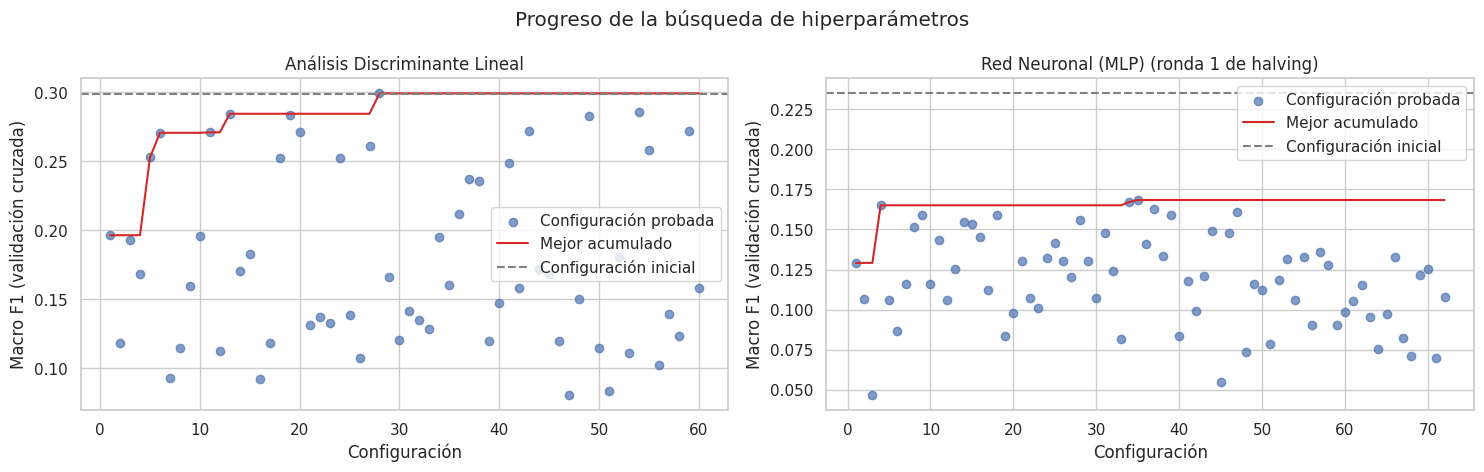


=== TOP 5 CONFIGURACIONES: Análisis Discriminante Lineal ===


,potencia_priors,shrinkage,solver,reductor,scaler,tol,mean_test_score,std_test_score,mean_fit_time
27,0.9717,None,svd,passthrough,RobustScaler,0.002487,0.2993,0.0078,0.2001
53,0.5166,None,svd,passthrough,Cuantiles→normal,1.105e-05,0.2856,0.0195,0.5641
12,0.8332,None,svd,passthrough,Cuantiles→normal,4.937e-06,0.2845,0.0159,0.5671
18,0.3887,None,svd,passthrough,Cuantiles→normal,1.217e-05,0.2836,0.0201,0.5699
48,0.1507,None,svd,passthrough,Yeo-Johnson,0.0001078,0.2831,0.0138,1.3089



=== TOP 5 CONFIGURACIONES: Red Neuronal (MLP) ===


,ronda,activation,alpha,batch_size,hidden_layer_sizes,learning_rate_init,n_iter_no_change,scaler,mean_test_score,std_test_score,mean_fit_time
103,2,tanh,0.004676,128,"(256, 128, 64)",0.0003823,15,Yeo-Johnson,0.2471,0.0062,37.4933
101,2,tanh,1.079e-06,512,"(128,)",0.002592,15,Yeo-Johnson,0.2417,0.0133,7.2054
100,2,tanh,0.0004974,128,"(256, 128)",0.0004188,5,Yeo-Johnson,0.2407,0.0180,24.7512
97,2,tanh,6.685e-06,128,"(256, 128, 64)",0.0002619,15,RobustScaler,0.2403,0.0171,37.9806
99,2,tanh,7.418e-05,256,"(128, 64)",0.00124,10,StandardScaler,0.2394,0.0142,11.0175



=== MEJORA EN VALIDACIÓN CRUZADA AGRUPADA (misma partición para ambas configuraciones) ===


,Método,Configuraciones evaluadas,CV F1 inicial,CV F1 ajustado,Mejora,Folds con mejora,Configuración elegida,Duración (s)
Modelo,,,,,,,,
Análisis Discriminante Lineal,aleatoria,60,0.2986,0.2993,0.0006,3/3,ajustada,58.2299
Red Neuronal (MLP),halving,104,0.2348,0.2440,0.0092,2/3,ajustada,488.2774


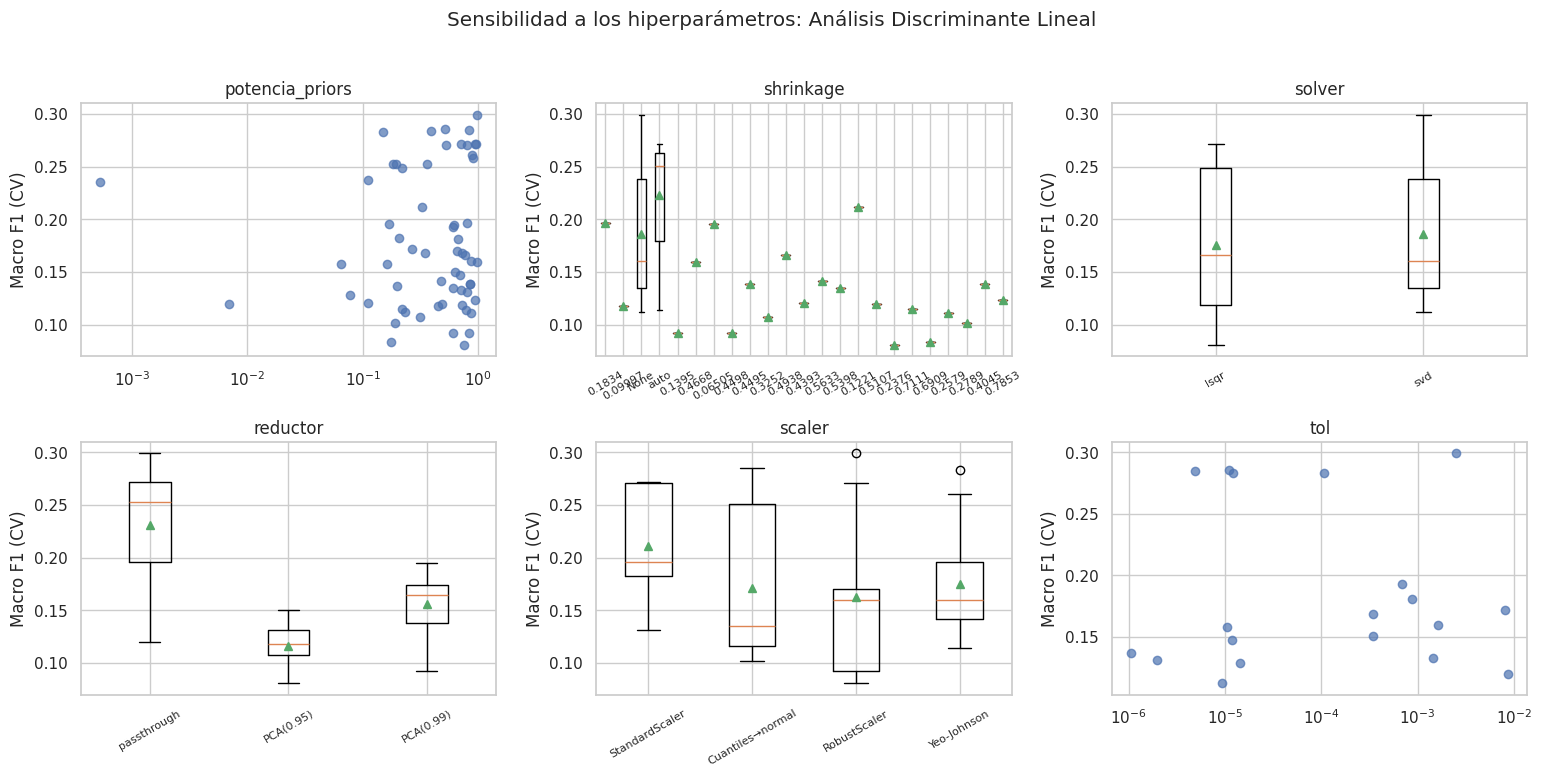

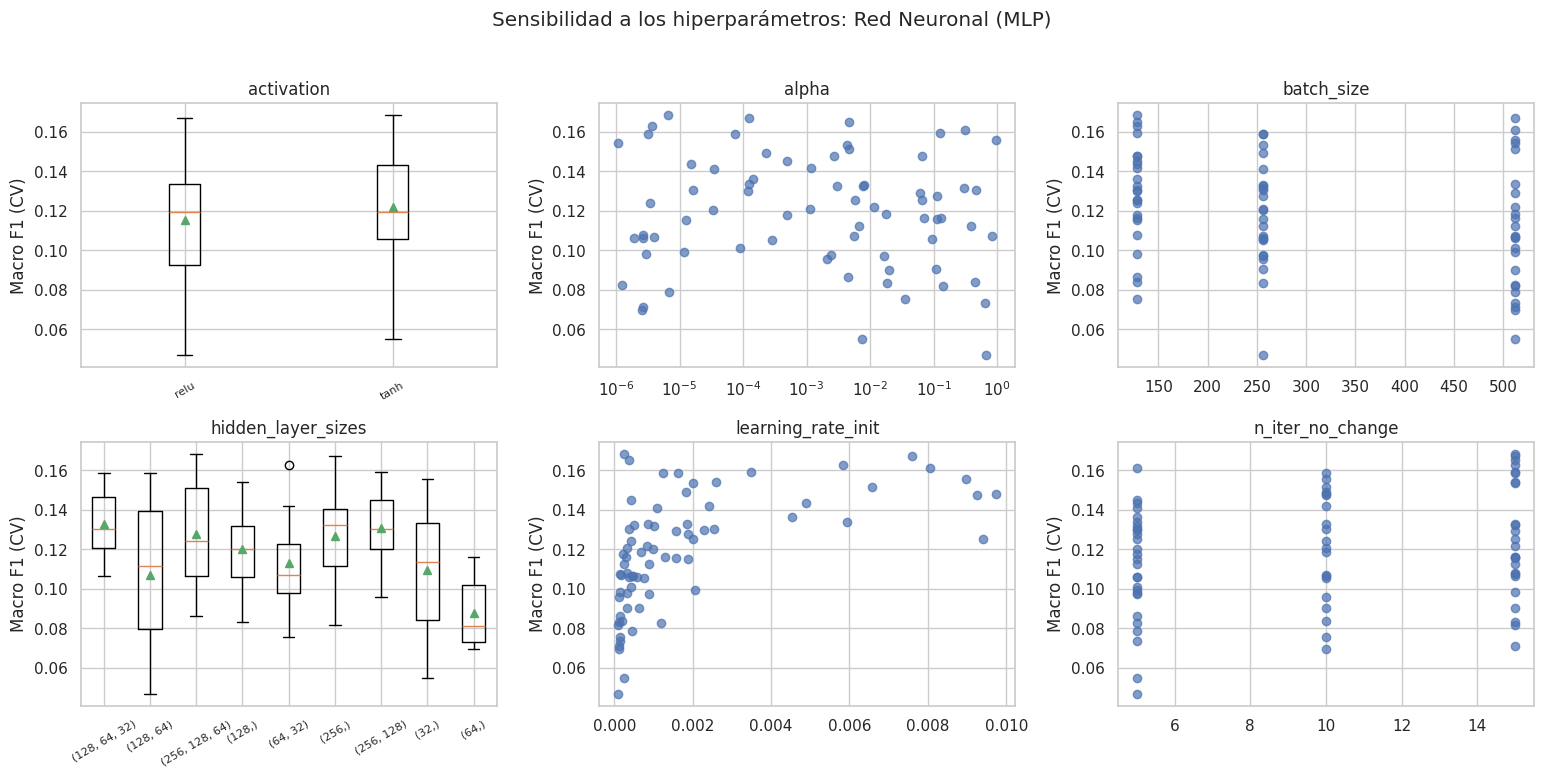

In [16]:
# ==============================================================================
# 4.3 RESULTADOS DE LA BÚSQUEDA: PROGRESO, TOP-5, MEJORA EN CV Y SENSIBILIDAD
# ==============================================================================

def resultados_comparables(nombre):
    """Resultados de la búsqueda comparables entre sí (misma cantidad de recursos)."""
    res = pd.DataFrame(busquedas[nombre]["busqueda"].cv_results_)
    if "iter" in res.columns:
        res = res[res["iter"] == 0]          # primera ronda de halving: todos con los mismos recursos
    return res.dropna(subset=["mean_test_score"])


# --- Progreso de la búsqueda ---
fig, ejes = plt.subplots(1, len(top2), figsize=(7.5 * len(top2), 4.8), squeeze=False)
for ax, nombre in zip(ejes[0], top2):
    res = resultados_comparables(nombre)
    puntajes = res["mean_test_score"].to_numpy()
    ax.scatter(range(1, len(puntajes) + 1), puntajes, alpha=0.7, label="Configuración probada")
    ax.plot(range(1, len(puntajes) + 1), np.maximum.accumulate(puntajes),
            color="tab:red", label="Mejor acumulado")
    ax.axhline(np.nanmean(busquedas[nombre]["cv_inicial"]), color="gray", linestyle="--",
               label="Configuración inicial")
    titulo_extra = " (ronda 1 de halving)" if busquedas[nombre]["metodo"] == "halving" else ""
    ax.set_title(nombre + titulo_extra)
    ax.set_xlabel("Configuración")
    ax.set_ylabel("Macro F1 (validación cruzada)")
    ax.legend()
plt.suptitle("Progreso de la búsqueda de hiperparámetros")
plt.tight_layout()
plt.show()

# --- Top-5 configuraciones ---
for nombre in top2:
    res = pd.DataFrame(busquedas[nombre]["busqueda"].cv_results_)
    columnas_parametros = [c for c in res.columns if c.startswith("param_")]
    if "iter" in res.columns:
        # halving: primero los finalistas (rondas con más recursos), luego por puntaje
        res = res.sort_values(["iter", "mean_test_score"], ascending=[False, False])
        extra = ["iter"]
    else:
        res = res.sort_values("rank_test_score")
        extra = []
    top_configs = (
        res[extra + columnas_parametros + ["mean_test_score", "std_test_score", "mean_fit_time"]]
        .head(5)
        .rename(columns=lambda c: "ronda" if c == "iter" else c.replace("param_clf__", "").replace("param_", ""))
    )
    for c in top_configs.columns:
        if c not in ["ronda", "mean_test_score", "std_test_score", "mean_fit_time"]:
            top_configs[c] = top_configs[c].map(nombre_corto)
    print(f"\n=== TOP 5 CONFIGURACIONES: {nombre} ===")
    display(top_configs.round(4))

# --- Mejora medida con la misma validación cruzada ---
filas_cv = []
for nombre in top2:
    b = busquedas[nombre]
    mejora_por_fold = b["cv_mejor"] - b["cv_inicial"]
    filas_cv.append({
        "Modelo": nombre,
        "Método": b["metodo"],
        "Configuraciones evaluadas": b["n_configs"],
        "CV F1 inicial": np.nanmean(b["cv_inicial"]),
        "CV F1 ajustado": np.nanmean(b["cv_mejor"]),
        "Mejora": np.nanmean(mejora_por_fold),
        "Folds con mejora": f"{int((mejora_por_fold > 0).sum())}/{len(mejora_por_fold)}",
        "Configuración elegida": "ajustada" if b["ajuste_exitoso"] else "inicial",
        "Duración (s)": b["duracion"],
    })
df_cv = pd.DataFrame(filas_cv).set_index("Modelo")
print("\n=== MEJORA EN VALIDACIÓN CRUZADA AGRUPADA (misma partición para ambas configuraciones) ===")
display(df_cv.round(4))

# --- Sensibilidad a los hiperparámetros ---
def graficar_sensibilidad(nombre, max_paneles=6):
    res = resultados_comparables(nombre)
    columnas = [c for c in res.columns if c.startswith("param_")
                and res[c].map(nombre_corto).nunique() > 1]
    columnas = columnas[:max_paneles]
    if not columnas:
        return
    n_cols = 3
    n_filas = int(np.ceil(len(columnas) / n_cols))
    fig, ejes = plt.subplots(n_filas, n_cols, figsize=(5.2 * n_cols, 3.8 * n_filas), squeeze=False)
    for ax in ejes.ravel()[len(columnas):]:
        ax.axis("off")
    for ax, col in zip(ejes.ravel(), columnas):
        etiqueta = col.replace("param_clf__", "").replace("param_", "")
        valores = res[col]
        try:
            numericos = pd.to_numeric(valores.astype(object), errors="raise").astype(float)
            ax.scatter(numericos, res["mean_test_score"], alpha=0.7)
            if numericos.min() > 0 and numericos.max() / numericos.min() > 100:
                ax.set_xscale("log")
        except Exception:
            categorias = valores.map(nombre_corto)
            orden = categorias.unique().tolist()
            datos_box = [res.loc[categorias == c, "mean_test_score"].to_numpy() for c in orden]
            ax.boxplot(datos_box, showmeans=True)
            ax.set_xticklabels(orden, rotation=30, fontsize=8)
        ax.set_title(etiqueta)
        ax.set_ylabel("Macro F1 (CV)")
    plt.suptitle(f"Sensibilidad a los hiperparámetros: {nombre}", y=1.02)
    plt.tight_layout()
    plt.show()


for nombre in top2:
    try:
        graficar_sensibilidad(nombre)
    except Exception as error:
        print(f"No se pudo graficar la sensibilidad de {nombre}:", repr(error)[:150])

=== EFECTO DEL AJUSTE FINO (VALIDACIÓN, fold 4) ===


,Modelo,Métrica,Configuración inicial,Ajustado,Cambio
0,Análisis Discriminante Lineal,Macro F1,0.3605,0.3610,0.0005
1,Análisis Discriminante Lineal,Accuracy,0.6094,0.6083,-0.0010
2,Análisis Discriminante Lineal,Macro IoU,0.2487,0.2488,0.0001
3,Análisis Discriminante Lineal,Brecha F1,0.0599,0.0632,0.0033
4,Red Neuronal (MLP),Macro F1,0.2905,0.3013,0.0109
5,Red Neuronal (MLP),Accuracy,0.5779,0.5537,-0.0242
6,Red Neuronal (MLP),Macro IoU,0.1957,0.2005,0.0048
7,Red Neuronal (MLP),Brecha F1,0.4697,0.5678,0.0982



=== SIGNIFICANCIA DE LA MEJORA (bootstrap pareado por parche) ===


,Δ Macro F1 (validación),IC95% de Δ,P(ajustado > inicial)
Modelo,,,
Análisis Discriminante Lineal,0.0006,"[-0.0008, 0.0021]",0.767
Red Neuronal (MLP),0.0084,"[-0.0148, 0.0332]",0.749


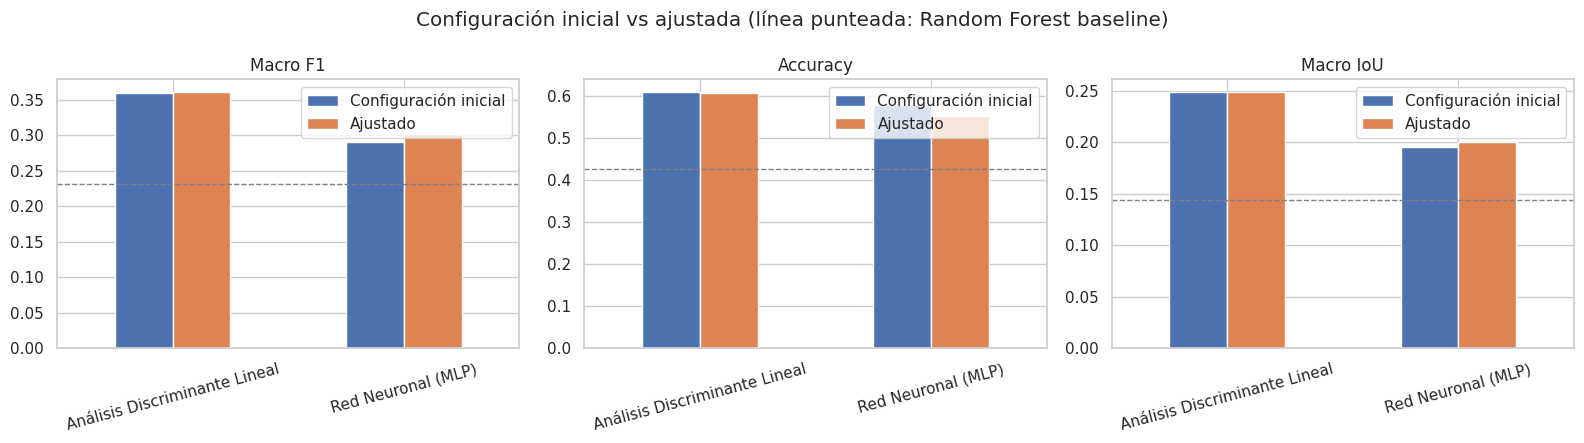

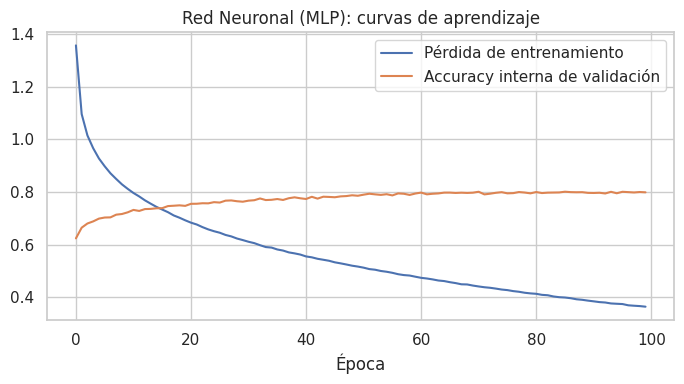

In [17]:
# ==============================================================================
# 4.4 REENTRENAMIENTO CON LOS MEJORES HIPERPARÁMETROS (ANTES vs DESPUÉS)
# ==============================================================================

modelos_ajustados = {}
registros_ajustados = []

for nombre in top2:
    X_tr, y_tr, _ = datos_entrenamiento(nombre)

    modelo = crear_modelos(n_jobs=-1)[nombre]
    modelo.set_params(**clone(busquedas[nombre]["params_elegidos"], safe=False))

    resultado = entrenar_y_evaluar(nombre, modelo, X_tr, y_tr, clave=f"{nombre} (ajustado)")
    modelos_ajustados[nombre] = modelo
    registros_ajustados.append(resultado)

df_ajustados = pd.DataFrame(registros_ajustados).set_index("Modelo")

# Tabla antes / después
comparacion_ajuste = []
for nombre in top2:
    antes = df_resultados.loc[nombre]
    despues = df_ajustados.loc[nombre]

    for metrica in ["Macro F1", "Accuracy", "Macro IoU", "Brecha F1"]:
        comparacion_ajuste.append({
            "Modelo": nombre,
            "Métrica": metrica,
            "Configuración inicial": antes[metrica],
            "Ajustado": despues[metrica],
            "Cambio": despues[metrica] - antes[metrica],
        })

df_ajuste = pd.DataFrame(comparacion_ajuste)

print("=== EFECTO DEL AJUSTE FINO (VALIDACIÓN, fold 4) ===")
display(df_ajuste.round(4))

# Significancia de la mejora: bootstrap pareado por parche
for nombre in top2:
    clave = f"{nombre} (ajustado)"
    mats_val[clave] = matriz_por_parche(y_val, PRED_VAL[clave], g_val)
    boot_val[clave] = bootstrap_metricas(mats_val[clave], IDX_BOOT_VAL)

filas_sig = []
for nombre in top2:
    delta = boot_val[f"{nombre} (ajustado)"]["Macro F1"] - boot_val[nombre]["Macro F1"]
    lo, hi = intervalo(delta)
    filas_sig.append({"Modelo": nombre, "Δ Macro F1 (validación)": delta.mean(),
                      "IC95% de Δ": f"[{lo:.4f}, {hi:.4f}]",
                      "P(ajustado > inicial)": float((delta > 0).mean())})
df_significancia = pd.DataFrame(filas_sig).set_index("Modelo")
print("\n=== SIGNIFICANCIA DE LA MEJORA (bootstrap pareado por parche) ===")
display(df_significancia.round(4))

# Visualización
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metrica in zip(ejes, ["Macro F1", "Accuracy", "Macro IoU"]):
    sub = df_ajuste[df_ajuste["Métrica"] == metrica].set_index("Modelo")
    sub[["Configuración inicial", "Ajustado"]].plot(kind="bar", ax=ax, rot=15)
    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.axhline(fila_rf[metrica], color="gray", linestyle="--", linewidth=1)
plt.suptitle("Configuración inicial vs ajustada (línea punteada: Random Forest baseline)")
plt.tight_layout()
plt.show()

# Curva de pérdida si alguno de los modelos es una red neuronal
for nombre, modelo in modelos_ajustados.items():
    clf = modelo.named_steps["clf"]
    if hasattr(clf, "loss_curve_"):
        plt.figure(figsize=(7, 4))
        plt.plot(clf.loss_curve_, label="Pérdida de entrenamiento")
        if getattr(clf, "validation_scores_", None):
            plt.plot(clf.validation_scores_, label="Accuracy interna de validación")
        plt.title(f"{nombre}: curvas de aprendizaje")
        plt.xlabel("Época")
        plt.legend()
        plt.tight_layout()
        plt.show()

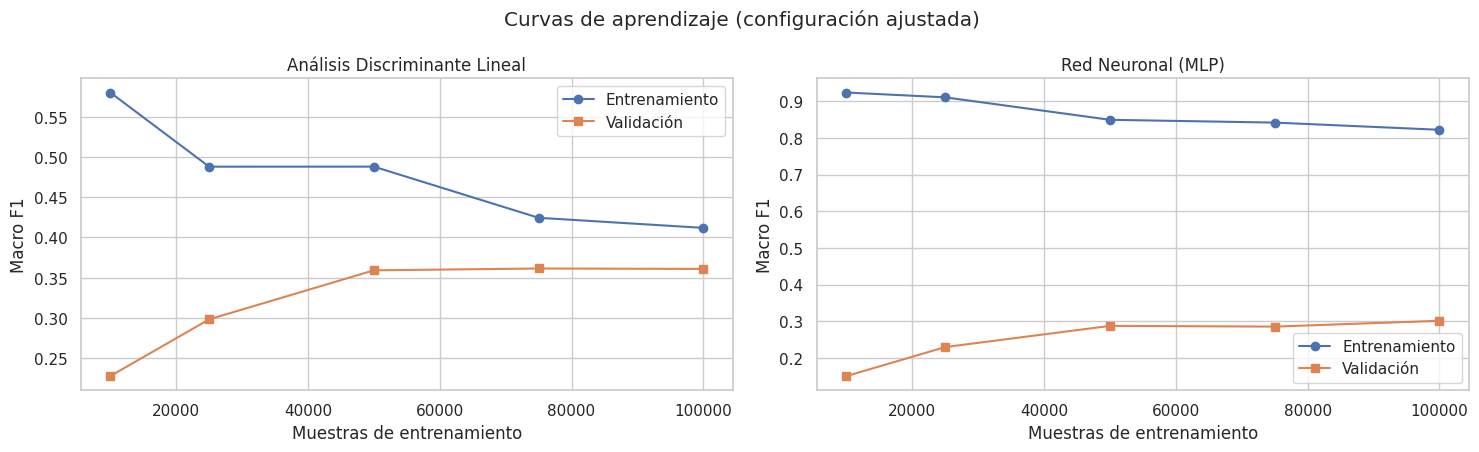

- **Análisis Discriminante Lineal**: de 75% a 100% de los parches el Macro F1 de validación cambia -0.0005; brecha final entrenamiento–validación = 0.051; la curva de validación se estabiliza: el límite está en la capacidad/representación, no en la cantidad de datos.
- **Red Neuronal (MLP)**: de 75% a 100% de los parches el Macro F1 de validación cambia +0.0158; brecha final entrenamiento–validación = 0.521; la curva de validación todavía crece: más datos probablemente mejorarían el modelo.

In [18]:
# ==============================================================================
# 4.5 CURVAS DE APRENDIZAJE DE LOS MODELOS AJUSTADOS (¿MÁS DATOS AYUDARÍAN?)
# ==============================================================================

def curva_aprendizaje(nombre, fracciones=(0.1, 0.25, 0.5, 0.75, 1.0)):
    """Entrena la configuración ajustada con fracciones crecientes de PARCHES y mide Macro F1."""
    X_tr, y_tr, g_tr = datos_entrenamiento(nombre)
    parches = np.unique(g_tr)
    orden = np.random.default_rng(SEED).permutation(parches)
    filas = []
    for fr in fracciones:
        elegidos = orden[: max(2, int(round(fr * len(orden))))]
        mascara = np.isin(g_tr, elegidos)
        modelo = clone(modelos_ajustados[nombre])
        modelo.fit(X_tr[mascara], y_tr[mascara])
        sub = np.flatnonzero(mascara)[:10_000]
        filas.append({
            "Fracción de parches": fr,
            "Muestras": int(mascara.sum()),
            "Macro F1 (entrenamiento)": f1_macro_presentes(y_tr[sub], modelo.predict(X_tr[sub])),
            "Macro F1 (validación)": f1_macro_presentes(y_val, modelo.predict(X_val)),
        })
    return pd.DataFrame(filas)


curvas = {nombre: curva_aprendizaje(nombre) for nombre in top2}

fig, ejes = plt.subplots(1, len(top2), figsize=(7.5 * len(top2), 4.6), squeeze=False)
for ax, nombre in zip(ejes[0], top2):
    c = curvas[nombre]
    ax.plot(c["Muestras"], c["Macro F1 (entrenamiento)"], marker="o", label="Entrenamiento")
    ax.plot(c["Muestras"], c["Macro F1 (validación)"], marker="s", label="Validación")
    ax.set_title(nombre)
    ax.set_xlabel("Muestras de entrenamiento")
    ax.set_ylabel("Macro F1")
    ax.legend()
plt.suptitle("Curvas de aprendizaje (configuración ajustada)")
plt.tight_layout()
plt.show()

lineas_curva = []
for nombre in top2:
    c = curvas[nombre]
    ganancia = c["Macro F1 (validación)"].iloc[-1] - c["Macro F1 (validación)"].iloc[-2]
    brecha = c["Macro F1 (entrenamiento)"].iloc[-1] - c["Macro F1 (validación)"].iloc[-1]
    if ganancia > 0.01:
        lectura = "la curva de validación todavía crece: más datos probablemente mejorarían el modelo"
    else:
        lectura = "la curva de validación se estabiliza: el límite está en la capacidad/representación, no en la cantidad de datos"
    lineas_curva.append(f"- **{nombre}**: de 75% a 100% de los parches el Macro F1 de validación cambia {ganancia:+.4f}; "
                        f"brecha final entrenamiento–validación = {brecha:.3f}; {lectura}.")
display(Markdown("\n".join(lineas_curva)))

## 5. Elección del Modelo Individual Final

La elección del modelo final no depende únicamente de la métrica principal. Se consideran también:

- **Desempeño:** Macro F1 (principal), Accuracy y Macro IoU, y el compromiso entre ellas (por ejemplo, ponderar clases suele subir Macro F1 a costa de Accuracy).
- **Generalización:** brecha entre entrenamiento y validación.
- **Costo computacional:** tiempo de entrenamiento y, sobre todo, de predicción, relevante porque PASTIS requiere clasificar millones de píxeles; también el tamaño del modelo serializado (almacenamiento y despliegue).
- **Interpretabilidad:** capacidad de explicar las decisiones del modelo ante un usuario agrícola o institucional.

**Regla de decisión.** Se elige el modelo con mayor Macro F1 en validación. Si la diferencia entre los dos candidatos es menor que la tolerancia definida (`TOLERANCIA_F1`), la diferencia se considera dentro del ruido y se prefiere el modelo más interpretable y, en caso de empate, el de menor tiempo de predicción.

**Análisis de robustez.** Como la ponderación de los criterios es una decisión del equipo, se evalúa una **matriz de decisión con tres escenarios** (priorizar desempeño, balanceado, priorizar operación y explicabilidad) para comprobar si la elección cambia al modificar las prioridades.

=== COMPARACIÓN DE LOS DOS MODELOS AJUSTADOS (VALIDACIÓN) ===


,Macro F1,Accuracy,Macro IoU,Brecha F1,Tiempo entrenamiento (s),Tiempo predicción (s),Tamaño (MB),Muestras de entrenamiento,Píxeles/s (predicción),Clasificar todo PASTIS (min),Interpretabilidad
Modelo,,,,,,,,,,,
Análisis Discriminante Lineal,0.3610,0.6083,0.2488,0.0632,0.5504,0.0131,0.0147,100000,2.288967e+06,0.2902,Alta: fronteras lineales y medias por clase
Red Neuronal (MLP),0.3013,0.5537,0.2005,0.5678,183.9135,0.1224,0.6846,100000,2.450497e+05,2.7112,Baja: caja negra; requiere explicabilidad post...


(Clasificar todo PASTIS = 39,862,272 píxeles; solo el costo de predicción, sin extracción de características.)

=== CRITERIOS NORMALIZADOS (1 = mejor candidato en ese criterio) ===


,Macro F1,Accuracy,Macro IoU,Generalización,Velocidad de predicción,Interpretabilidad
Modelo,,,,,,
Análisis Discriminante Lineal,1.000,1.00,1.000,1.000,1.000,1.000
Red Neuronal (MLP),0.835,0.91,0.806,0.111,0.107,0.333


=== MATRIZ DE DECISIÓN (puntaje ponderado por escenario) ===


,Prioriza desempeño,Balanceado,Prioriza operación y explicabilidad
Modelo,,,
Análisis Discriminante Lineal,1.000,1.000,1.000
Red Neuronal (MLP),0.708,0.558,0.425


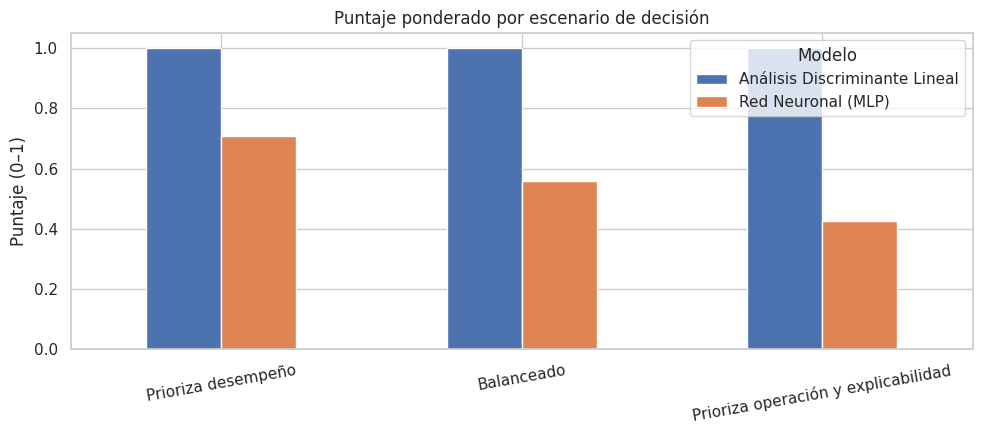


=== MODELO INDIVIDUAL FINAL: Análisis Discriminante Lineal ===
Motivo: supera al otro candidato por 0.0596 de Macro F1, diferencia mayor que la tolerancia de 0.01
P(supera a Red Neuronal (MLP) en Macro F1, bootstrap pareado): 100%  | IC95% de la diferencia: [0.0369, 0.0816]
Robustez: el modelo final gana en 3 de 3 escenarios de la matriz de decisión.


In [19]:
# ==============================================================================
# 5.1 TRADE-OFFS ENTRE LOS DOS MODELOS AJUSTADOS Y SELECCIÓN FINAL
# ==============================================================================

TOLERANCIA_F1 = 0.01
PIXELES_DATASET = len(metadata) * 128 * 128      # PASTIS: 2,433 parches de 128 × 128 píxeles

# Valoración cualitativa de interpretabilidad (mayor = más interpretable)
INTERPRETABILIDAD = {
    "Regresión Logística": (3, "Alta: coeficientes por clase y característica"),
    "Árbol de Decisión": (3, "Alta: reglas explícitas, aunque inestables"),
    "Análisis Discriminante Lineal": (3, "Alta: fronteras lineales y medias por clase"),
    "Naive Bayes Gaussiano": (3, "Alta: probabilidades por característica"),
    "K-Vecinos más Cercanos": (2, "Media: explica por ejemplos vecinos"),
    "SVM (kernel RBF)": (1, "Baja: vectores de soporte sin explicación directa"),
    "Red Neuronal (MLP)": (1, "Baja: caja negra; requiere explicabilidad posterior"),
}

tabla_final = df_ajustados[[
    "Macro F1", "Accuracy", "Macro IoU", "Brecha F1",
    "Tiempo entrenamiento (s)", "Tiempo predicción (s)", "Tamaño (MB)",
    "Muestras de entrenamiento"
]].copy()
tabla_final["Píxeles/s (predicción)"] = len(y_val) / tabla_final["Tiempo predicción (s)"]
tabla_final["Clasificar todo PASTIS (min)"] = PIXELES_DATASET / tabla_final["Píxeles/s (predicción)"] / 60
tabla_final["Interpretabilidad"] = [INTERPRETABILIDAD[m][1] for m in tabla_final.index]

print("=== COMPARACIÓN DE LOS DOS MODELOS AJUSTADOS (VALIDACIÓN) ===")
display(tabla_final.round(4))
print(f"(Clasificar todo PASTIS = {PIXELES_DATASET:,} píxeles; solo el costo de predicción, sin extracción de características.)")

candidatos = tabla_final.sort_values("Macro F1", ascending=False)
primero, segundo = candidatos.index[0], candidatos.index[1]
diferencia = candidatos.loc[primero, "Macro F1"] - candidatos.loc[segundo, "Macro F1"]

if diferencia >= TOLERANCIA_F1:
    modelo_final_nombre = primero
    motivo_regla = (f"supera al otro candidato por {diferencia:.4f} de Macro F1, "
                    f"diferencia mayor que la tolerancia de {TOLERANCIA_F1}")
else:
    desempate = sorted(
        [primero, segundo],
        key=lambda m: (-INTERPRETABILIDAD[m][0], candidatos.loc[m, "Tiempo predicción (s)"])
    )
    modelo_final_nombre = desempate[0]
    motivo_regla = (f"la diferencia de Macro F1 ({diferencia:.4f}) es menor que la tolerancia de "
                    f"{TOLERANCIA_F1}; se prefiere el modelo más interpretable y rápido de predecir")

modelo_final = modelos_ajustados[modelo_final_nombre]
fila_final = tabla_final.loc[modelo_final_nombre]
otro_nombre = segundo if modelo_final_nombre == primero else primero

# Evidencia estadística de la elección (bootstrap pareado en validación)
clave_final, clave_otro = f"{modelo_final_nombre} (ajustado)", f"{otro_nombre} (ajustado)"
delta_eleccion = boot_val[clave_final]["Macro F1"] - boot_val[clave_otro]["Macro F1"]
p_final_sobre_otro = float((delta_eleccion > 0).mean())
ic_delta_eleccion = intervalo(delta_eleccion)

# ------------------------------------------------------------------------------
# Matriz de decisión: la elección ¿cambia si cambian las prioridades?
# ------------------------------------------------------------------------------
def puntuar_criterios(tabla):
    """Cada criterio se escala a [0, 1] respecto al mejor de los candidatos (1 = mejor)."""
    c = pd.DataFrame(index=tabla.index)
    c["Macro F1"] = tabla["Macro F1"] / tabla["Macro F1"].max()
    c["Accuracy"] = tabla["Accuracy"] / tabla["Accuracy"].max()
    c["Macro IoU"] = tabla["Macro IoU"] / tabla["Macro IoU"].max()
    brecha = tabla["Brecha F1"].clip(lower=1e-3)
    c["Generalización"] = brecha.min() / brecha
    c["Velocidad de predicción"] = tabla["Tiempo predicción (s)"].min() / tabla["Tiempo predicción (s)"]
    c["Interpretabilidad"] = [INTERPRETABILIDAD[m][0] / 3 for m in tabla.index]
    return c


ESCENARIOS = {
    "Prioriza desempeño": {"Macro F1": 0.50, "Accuracy": 0.15, "Macro IoU": 0.15,
                           "Generalización": 0.10, "Velocidad de predicción": 0.05, "Interpretabilidad": 0.05},
    "Balanceado": {"Macro F1": 0.35, "Accuracy": 0.10, "Macro IoU": 0.10,
                   "Generalización": 0.15, "Velocidad de predicción": 0.10, "Interpretabilidad": 0.20},
    "Prioriza operación y explicabilidad": {"Macro F1": 0.20, "Accuracy": 0.10, "Macro IoU": 0.05,
                                            "Generalización": 0.20, "Velocidad de predicción": 0.20,
                                            "Interpretabilidad": 0.25},
}

criterios = puntuar_criterios(tabla_final)
print("\n=== CRITERIOS NORMALIZADOS (1 = mejor candidato en ese criterio) ===")
display(criterios.round(3))

puntajes_escenarios = pd.DataFrame({
    escenario: criterios[list(pesos)].mul(pd.Series(pesos)).sum(axis=1)
    for escenario, pesos in ESCENARIOS.items()
})
ganadores_escenarios = puntajes_escenarios.idxmax()

print("=== MATRIZ DE DECISIÓN (puntaje ponderado por escenario) ===")
display(puntajes_escenarios.round(3))

puntajes_escenarios.T.plot(kind="bar", figsize=(10, 4.5), rot=10)
plt.title("Puntaje ponderado por escenario de decisión")
plt.ylabel("Puntaje (0–1)")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

coincide = int((ganadores_escenarios == modelo_final_nombre).sum())

print(f"\n=== MODELO INDIVIDUAL FINAL: {modelo_final_nombre} ===")
print("Motivo:", motivo_regla)
print(f"P(supera a {otro_nombre} en Macro F1, bootstrap pareado): {p_final_sobre_otro:.0%}  "
      f"| IC95% de la diferencia: [{ic_delta_eleccion[0]:.4f}, {ic_delta_eleccion[1]:.4f}]")
print(f"Robustez: el modelo final gana en {coincide} de {len(ESCENARIOS)} escenarios de la matriz de decisión.")

=== ANÁLISIS DISCRIMINANTE LINEAL - CONJUNTO DE PRUEBA ===
Accuracy: 0.5996   (IC 95%: [0.5396, 0.6558])
Macro F1: 0.3031   (IC 95%: [0.2572, 0.3357])
Macro IoU: 0.2128   (IC 95%: [0.1770, 0.2443])
Tiempo de predicción en prueba: 0.01 s para 30,000 píxeles

=== DESEMPEÑO POR CLASE (PRUEBA) ===


,precision,recall,f1-score,support
0 · Fondo,0.695,0.766,0.729,11805.0
1 · Pradera,0.695,0.676,0.685,5226.0
2 · Trigo blando de invierno,0.559,0.814,0.662,2231.0
3 · Maíz,0.757,0.579,0.656,2413.0
4 · Cebada de invierno,0.145,0.125,0.134,448.0
5 · Colza de invierno,0.758,0.830,0.792,622.0
6 · Cebada de primavera,0.062,0.004,0.007,271.0
7 · Girasol,0.228,0.199,0.213,392.0
8 · Vid,0.421,0.541,0.474,1523.0
9 · Remolacha,0.250,0.644,0.360,73.0


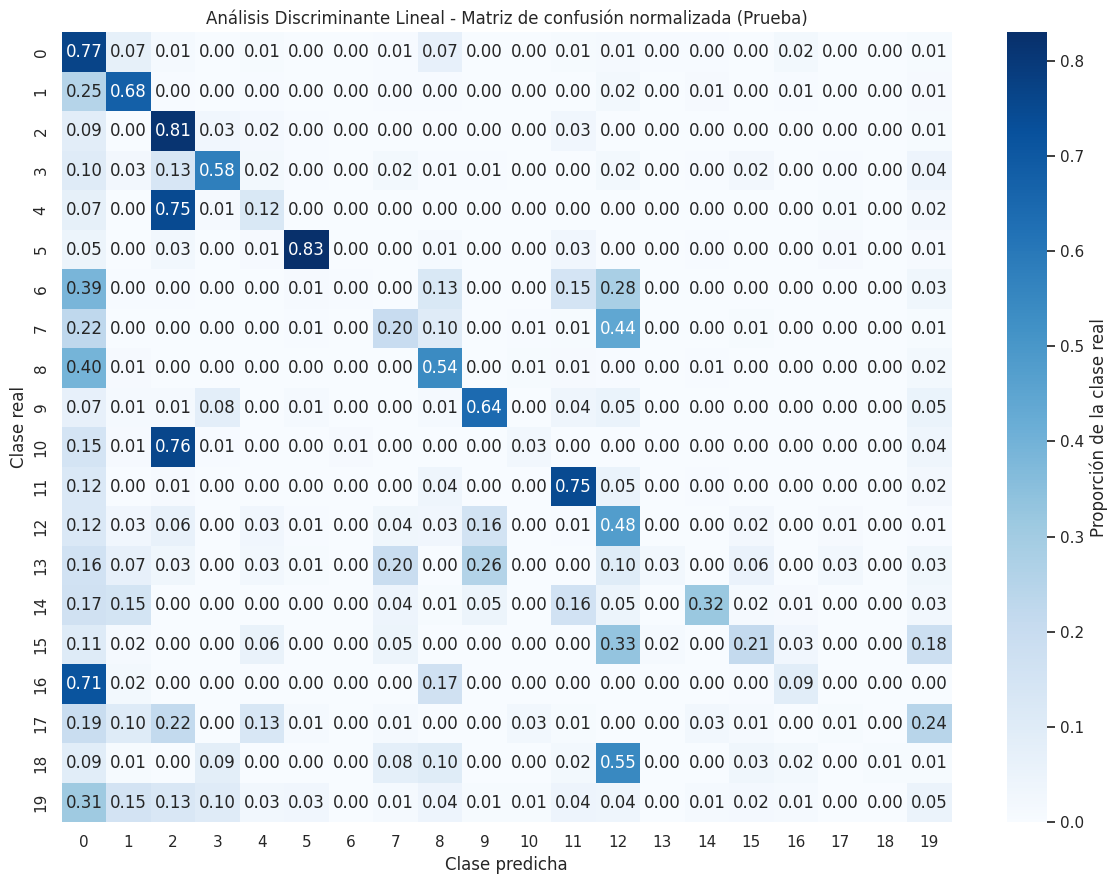

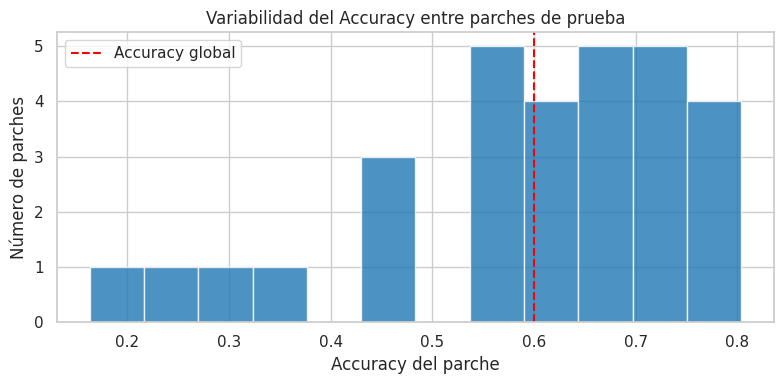

Accuracy por parche: mínimo 0.163 | mediana 0.634 | máximo 0.804


In [20]:
# ==============================================================================
# 5.2 EVALUACIÓN ÚNICA EN EL CONJUNTO DE PRUEBA (fold 5)
# ==============================================================================

t0 = time.time()
pred_test = modelo_final.predict(X_test)
t_pred_test = time.time() - t0

metricas_test = metricas(y_test, pred_test)

# Intervalos de confianza por bootstrap de parches (mismo procedimiento que en validación)
mats_test = matriz_por_parche(y_test, pred_test, g_test)
n_parches_test = len(np.unique(g_test))
IDX_BOOT_TEST = indices_bootstrap(n_parches_test, N_BOOTSTRAP, SEED + 1)
boot_test_final = bootstrap_metricas(mats_test, IDX_BOOT_TEST)
ic_test = {m: intervalo(boot_test_final[m]) for m in ["Accuracy", "Macro F1", "Macro IoU"]}

for m in ["Accuracy", "Macro F1", "Macro IoU"]:
    assert np.isclose(metricas_desde_matrices(mats_test.sum(axis=0))[m], metricas_test[m], atol=1e-9)

print(f"=== {modelo_final_nombre.upper()} - CONJUNTO DE PRUEBA ===")
for nombre_metrica, valor in metricas_test.items():
    lo, hi = ic_test[nombre_metrica]
    print(f"{nombre_metrica}: {valor:.4f}   (IC 95%: [{lo:.4f}, {hi:.4f}])")
print(f"Tiempo de predicción en prueba: {t_pred_test:.2f} s para {len(y_test):,} píxeles")

# Reporte por clase
clases_test = np.unique(y_test)
reporte = pd.DataFrame(classification_report(
    y_test, pred_test, labels=clases_test, output_dict=True, zero_division=0
)).T
reporte.index = [f"{i} · {NOMBRES_CLASES[int(i)]}" if str(i).isdigit() else i for i in reporte.index]

print("\n=== DESEMPEÑO POR CLASE (PRUEBA) ===")
display(reporte.round(3))

# Matriz de confusión normalizada por clase real
matriz = confusion_matrix(y_test, pred_test, labels=clases_test, normalize="true")

plt.figure(figsize=(12, 9))
sns.heatmap(matriz, annot=len(clases_test) <= 20, fmt=".2f", cmap="Blues",
            xticklabels=clases_test, yticklabels=clases_test,
            cbar_kws={"label": "Proporción de la clase real"})
plt.title(f"{modelo_final_nombre} - Matriz de confusión normalizada (Prueba)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

# Variabilidad del desempeño entre parches
tp_parche = np.diagonal(mats_test, axis1=-2, axis2=-1).sum(axis=-1)
acc_parche = tp_parche / mats_test.sum(axis=(-2, -1))

plt.figure(figsize=(8, 4))
plt.hist(acc_parche, bins=12, color="tab:blue", alpha=0.8)
plt.axvline(metricas_test["Accuracy"], color="red", linestyle="--", label="Accuracy global")
plt.title("Variabilidad del Accuracy entre parches de prueba")
plt.xlabel("Accuracy del parche")
plt.ylabel("Número de parches")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Accuracy por parche: mínimo {acc_parche.min():.3f} | mediana {np.median(acc_parche):.3f} | máximo {acc_parche.max():.3f}")

=== IMPORTANCIA POR PERMUTACIÓN: Análisis Discriminante Lineal ===
Tiempo de cálculo: 2.4 segundos



,Característica,Caída de Macro F1,Desviación
5,media_B7,0.2674,0.0124
4,media_B6,0.2667,0.0055
18,std_B7,0.2461,0.0017
17,std_B6,0.2404,0.0144
1,media_B3,0.2345,0.0097
7,media_B8A,0.2303,0.0145
16,std_B5,0.2197,0.0052
14,std_B3,0.2062,0.0091
20,std_B8A,0.1988,0.0101
3,media_B5,0.1853,0.0009


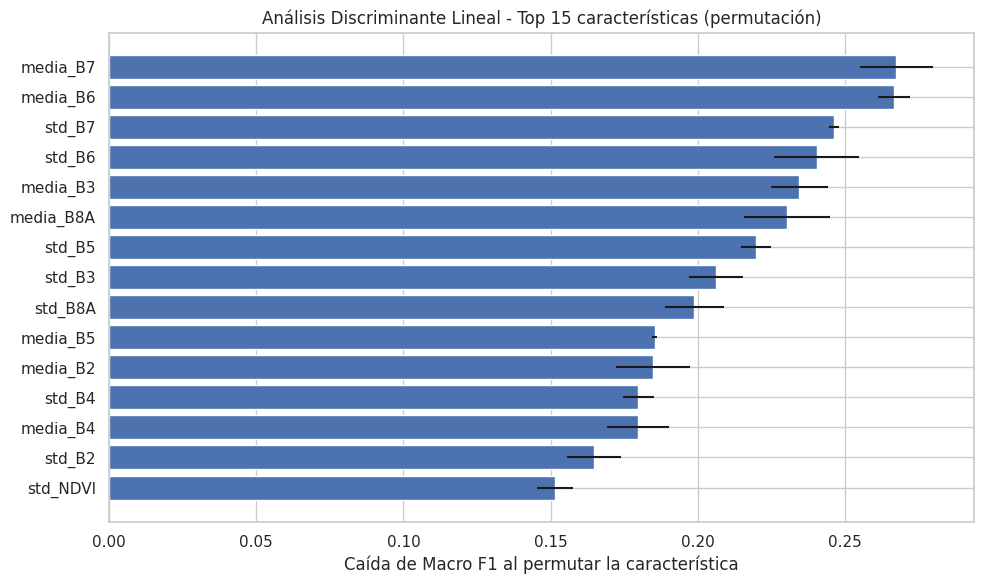

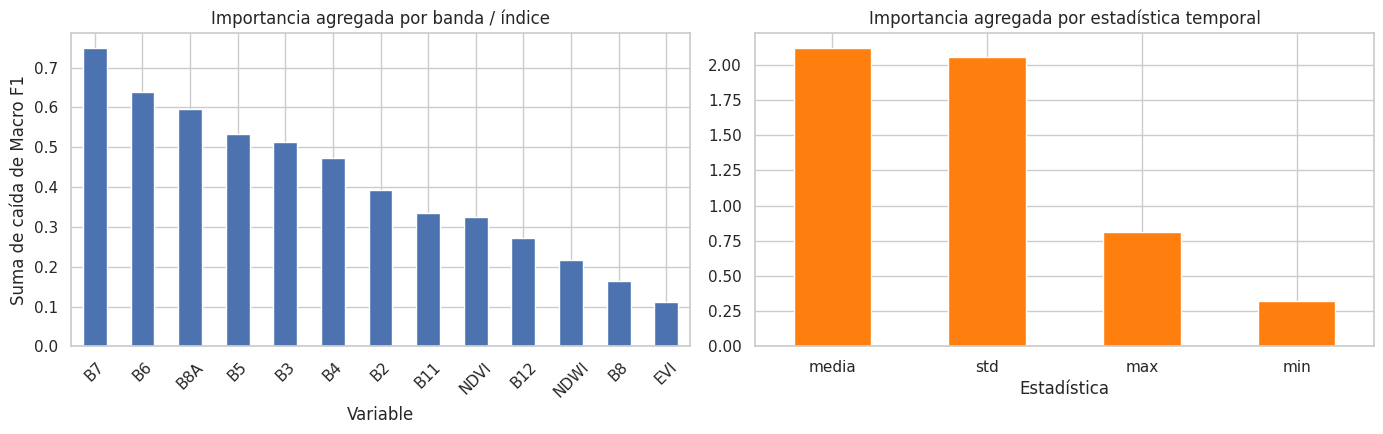

Importancia total por estadística temporal:


,Caída de Macro F1
Estadística,
media,2.1211
std,2.0591
max,0.8156
min,0.3251


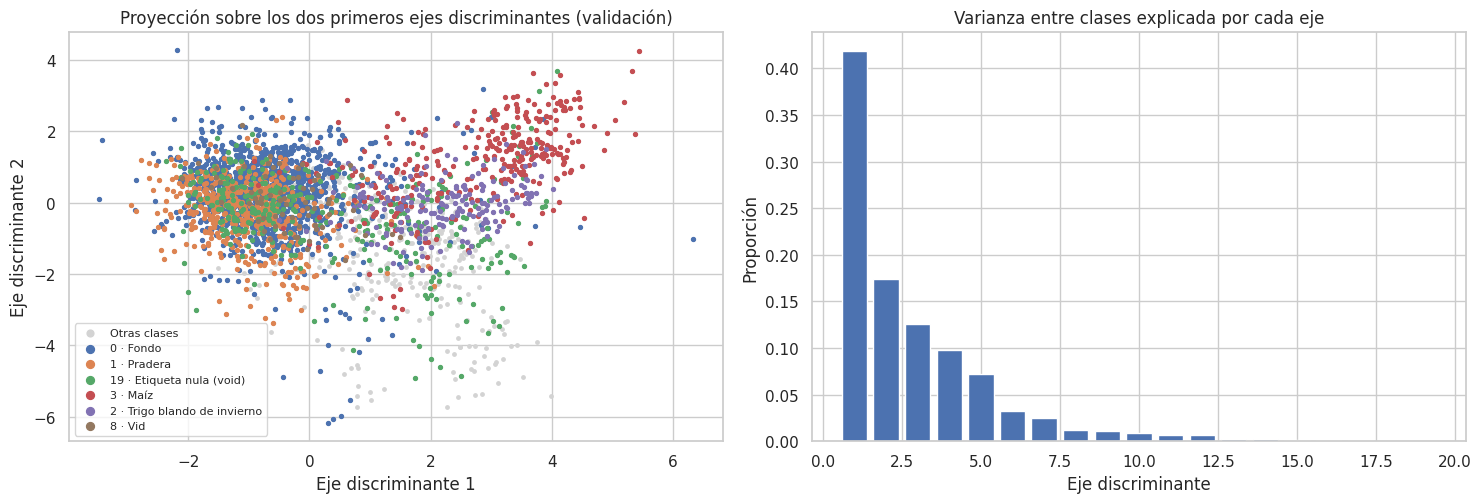

In [21]:
# ==============================================================================
# 5.3 INTERPRETABILIDAD: IMPORTANCIA POR PERMUTACIÓN Y ESTRUCTURA DEL MODELO
# ==============================================================================

# Se calcula en validación (no en prueba) y sobre una submuestra para acotar el costo
g = np.random.default_rng(SEED)
idx_perm = g.choice(len(X_val), size=min(3000, len(X_val)), replace=False)

t0 = time.time()
importancia = permutation_importance(
    modelo_final, X_val[idx_perm], y_val[idx_perm],
    scoring=scorer_f1, n_repeats=3, random_state=SEED, n_jobs=N_JOBS
)

df_importancia = pd.DataFrame({
    "Característica": nombres_features,
    "Caída de Macro F1": importancia.importances_mean,
    "Desviación": importancia.importances_std,
}).sort_values("Caída de Macro F1", ascending=False)

print(f"=== IMPORTANCIA POR PERMUTACIÓN: {modelo_final_nombre} ===")
print(f"Tiempo de cálculo: {time.time() - t0:.1f} segundos\n")
display(df_importancia.head(15).round(4))

top15 = df_importancia.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top15["Característica"][::-1], top15["Caída de Macro F1"][::-1],
         xerr=top15["Desviación"][::-1])
plt.title(f"{modelo_final_nombre} - Top 15 características (permutación)")
plt.xlabel("Caída de Macro F1 al permutar la característica")
plt.tight_layout()
plt.show()

# Importancia agrupada por tipo de variable y por estadística temporal
df_importancia["Variable"] = df_importancia["Característica"].str.split("_", n=1).str[1]
df_importancia["Estadística"] = df_importancia["Característica"].str.split("_", n=1).str[0]

por_estadistica = df_importancia.groupby("Estadística")["Caída de Macro F1"].sum().sort_values(ascending=False)
por_variable = df_importancia.groupby("Variable")["Caída de Macro F1"].sum().sort_values(ascending=False)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
por_variable.plot(kind="bar", ax=ejes[0], rot=45)
ejes[0].set_title("Importancia agregada por banda / índice")
ejes[0].set_ylabel("Suma de caída de Macro F1")
por_estadistica.plot(kind="bar", ax=ejes[1], rot=0, color="tab:orange")
ejes[1].set_title("Importancia agregada por estadística temporal")
plt.tight_layout()
plt.show()

print("Importancia total por estadística temporal:")
display(por_estadistica.round(4).to_frame())

# Estructura del modelo final: proyección discriminante (solo si es un LDA con solver svd/eigen)
clf_final = modelo_final.named_steps["clf"]
if isinstance(clf_final, LinearDiscriminantAnalysis) and clf_final.solver in ("svd", "eigen"):
    try:
        Z = modelo_final[:-1].transform(X_val[idx_perm])
        P = clf_final.transform(Z)
        y_perm = y_val[idx_perm].astype(int)
        principales = np.argsort(-np.bincount(y_perm, minlength=20))[:6]

        fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))
        ejes[0].scatter(P[:, 0], P[:, 1], c="lightgray", s=6, label="Otras clases")
        for clase in principales:
            m = y_perm == clase
            ejes[0].scatter(P[m, 0], P[m, 1], s=8, label=f"{clase} · {NOMBRES_CLASES[clase]}")
        ejes[0].set_title("Proyección sobre los dos primeros ejes discriminantes (validación)")
        ejes[0].set_xlabel("Eje discriminante 1")
        ejes[0].set_ylabel("Eje discriminante 2")
        ejes[0].legend(markerscale=2, fontsize=8)

        if hasattr(clf_final, "explained_variance_ratio_"):
            varianza = clf_final.explained_variance_ratio_
            ejes[1].bar(range(1, len(varianza) + 1), varianza)
            ejes[1].set_title("Varianza entre clases explicada por cada eje")
            ejes[1].set_xlabel("Eje discriminante")
            ejes[1].set_ylabel("Proporción")
        plt.tight_layout()
        plt.show()
    except Exception as error:
        print("No se pudo generar la proyección discriminante:", repr(error)[:150])
else:
    print("La proyección discriminante solo aplica cuando el modelo final es un LDA con solver 'svd' o 'eigen'.")

=== MODELO FINAL VS BASELINE VS UMBRALES (PRUEBA, fold 5) ===


,Mínimo esperado,Random Forest (baseline),Análisis Discriminante Lineal (final),IC95% (modelo final),Cumple (modelo final),P(superar el mínimo),Cambio vs baseline,P(final > baseline)
Accuracy,0.6,0.4320,0.5996,"[0.540, 0.656]",No cumple,0.506,0.1676,1.0
Macro F1,0.3,0.2064,0.3031,"[0.257, 0.336]",Cumple,0.461,0.0966,1.0
Macro IoU,0.2,0.1309,0.2128,"[0.177, 0.244]",Cumple,0.721,0.0818,1.0



Criterios cumplidos: 2 de 3
Nota: 'P(superar el mínimo)' es la proporción de remuestreos de parches en que el modelo supera el umbral; valores cercanos a 50% indican que el cumplimiento es frágil.


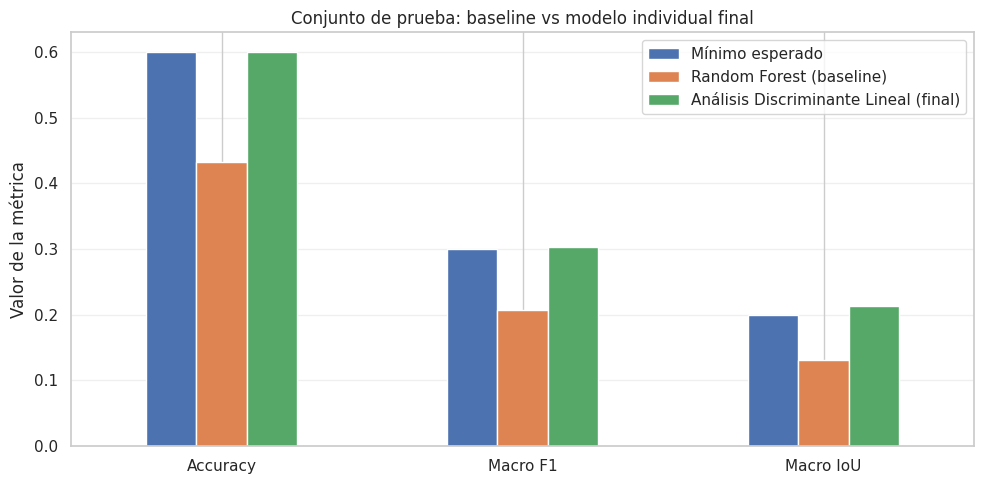

In [22]:
# ==============================================================================
# 5.4 DESEMPEÑO MÍNIMO ACEPTABLE Y COMPARACIÓN CONTRA EL BASELINE (PRUEBA)
# ==============================================================================

# Umbrales exploratorios definidos en el Avance 3
umbrales = {"Accuracy": 0.60, "Macro F1": 0.30, "Macro IoU": 0.20}

# Random Forest de referencia evaluado en prueba (misma función de métricas)
pred_rf_test = rf_referencia.predict(X_test)
metricas_rf_test = metricas(y_test, pred_rf_test)
mats_test_rf = matriz_por_parche(y_test, pred_rf_test, g_test)
boot_test_rf = bootstrap_metricas(mats_test_rf, IDX_BOOT_TEST)

comparacion_test = pd.DataFrame({
    "Mínimo esperado": umbrales,
    "Random Forest (baseline)": metricas_rf_test,
    f"{modelo_final_nombre} (final)": metricas_test,
})
comparacion_test["IC95% (modelo final)"] = [
    f"[{ic_test[m][0]:.3f}, {ic_test[m][1]:.3f}]" for m in comparacion_test.index
]
comparacion_test["Cumple (modelo final)"] = [
    "Cumple" if metricas_test[m] >= umbrales[m] else "No cumple"
    for m in comparacion_test.index
]
comparacion_test["P(superar el mínimo)"] = [
    float((boot_test_final[m] >= umbrales[m]).mean()) for m in comparacion_test.index
]
comparacion_test["Cambio vs baseline"] = (
    comparacion_test[f"{modelo_final_nombre} (final)"]
    - comparacion_test["Random Forest (baseline)"]
)
comparacion_test["P(final > baseline)"] = [
    float((boot_test_final[m] > boot_test_rf[m]).mean()) for m in comparacion_test.index
]

print("=== MODELO FINAL VS BASELINE VS UMBRALES (PRUEBA, fold 5) ===")
display(comparacion_test.round(4))

criterios_cumplidos = (comparacion_test["Cumple (modelo final)"] == "Cumple").sum()
print(f"\nCriterios cumplidos: {criterios_cumplidos} de {len(umbrales)}")
print("Nota: 'P(superar el mínimo)' es la proporción de remuestreos de parches en que el modelo supera el umbral; "
      "valores cercanos a 50% indican que el cumplimiento es frágil.")

ax = comparacion_test[["Mínimo esperado", "Random Forest (baseline)",
                       f"{modelo_final_nombre} (final)"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
plt.title("Conjunto de prueba: baseline vs modelo individual final")
plt.ylabel("Valor de la métrica")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# ==============================================================================
# 5.5 ANÁLISIS DE ERRORES DEL MODELO FINAL (PRUEBA)
# ==============================================================================

conf = confusion_matrix(y_test, pred_test, labels=CLASES)
soporte = conf.sum(axis=1)
fuera_diag = conf.copy()
np.fill_diagonal(fuera_diag, 0)

# Confusiones más frecuentes (clase real -> clase predicha)
filas_conf = []
for i in range(K):
    for j in range(K):
        if i != j and fuera_diag[i, j] > 0:
            filas_conf.append({
                "Clase real": f"{i} · {NOMBRES_CLASES[i]}",
                "Predicha como": f"{j} · {NOMBRES_CLASES[j]}",
                "Píxeles": int(fuera_diag[i, j]),
                "% de la clase real": 100 * fuera_diag[i, j] / max(soporte[i], 1),
            })
df_confusiones = pd.DataFrame(filas_conf).sort_values("Píxeles", ascending=False)
print("=== 10 CONFUSIONES MÁS FRECUENTES ===")
display(df_confusiones.head(10).round(1).reset_index(drop=True))

# Clases con peor desempeño y su error dominante
f1_test = f1_score(y_test, pred_test, labels=CLASES, average=None, zero_division=0)
filas_debiles = []
for c in clases_test:
    if f1_test[c] < 0.15:
        j = int(np.argmax(fuera_diag[c]))
        filas_debiles.append({
            "Clase": f"{c} · {NOMBRES_CLASES[c]}",
            "Soporte (píxeles)": int(soporte[c]),
            "F1": f1_test[c],
            "Recall": conf[c, c] / max(soporte[c], 1),
            "Error dominante": f"→ {j} · {NOMBRES_CLASES[j]}",
            "% hacia esa clase": 100 * fuera_diag[c, j] / max(soporte[c], 1),
        })
columnas_debiles = ["Clase", "Soporte (píxeles)", "F1", "Recall", "Error dominante", "% hacia esa clase"]
df_debiles = pd.DataFrame(filas_debiles, columns=columnas_debiles).sort_values("Soporte (píxeles)", ascending=False)
print("\n=== CLASES CON F1 < 0.15 ===")
display(df_debiles.round(3).reset_index(drop=True))

errores_por_clase = pd.Series(fuera_diag.sum(axis=1), index=[f"{c} · {NOMBRES_CLASES[c]}" for c in CLASES])
errores_por_clase = errores_por_clase.sort_values(ascending=False)
aporte_top3 = errores_por_clase.head(3).sum() / errores_por_clase.sum()

display(Markdown(f"""
**Lectura.** {len(df_debiles)} de {len(clases_test)} clases tienen F1 < 0.15; las clases con bajo F1 suelen ser minoritarias o tener una firma espectral/temporal parecida a otra
(véase la columna «Error dominante»). Las tres clases con más píxeles mal clasificados concentran el **{aporte_top3:.0%}** de los errores:
{', '.join(errores_por_clase.head(3).index)}. Esto indica dónde conviene concentrar el trabajo del siguiente avance (pesos por clase, remuestreo, contexto espacial).
"""))

=== 10 CONFUSIONES MÁS FRECUENTES ===


,Clase real,Predicha como,Píxeles,% de la clase real
0,1 · Pradera,0 · Fondo,1309,25.0
1,19 · Etiqueta nula (void),0 · Fondo,948,31.0
2,0 · Fondo,1 · Pradera,872,7.4
3,0 · Fondo,8 · Vid,813,6.9
4,8 · Vid,0 · Fondo,602,39.5
5,19 · Etiqueta nula (void),1 · Pradera,473,15.5
6,19 · Etiqueta nula (void),2 · Trigo blando de invierno,387,12.7
7,4 · Cebada de invierno,2 · Trigo blando de invierno,335,74.8
8,3 · Maíz,2 · Trigo blando de invierno,325,13.5
9,19 · Etiqueta nula (void),3 · Maíz,315,10.3



=== CLASES CON F1 < 0.15 ===


,Clase,Soporte (píxeles),F1,Recall,Error dominante,% hacia esa clase
0,19 · Etiqueta nula (void),3058,0.085,0.050,→ 0 · Fondo,31.001
1,4 · Cebada de invierno,448,0.134,0.125,→ 2 · Trigo blando de invierno,74.777
2,6 · Cebada de primavera,271,0.007,0.004,→ 0 · Fondo,38.745
3,16 · Huerto,203,0.071,0.094,→ 0 · Fondo,71.429
4,10 · Triticale de invierno,188,0.038,0.027,→ 2 · Trigo blando de invierno,76.064
5,"12 · Frutas, hortalizas y flores",171,0.149,0.480,→ 9 · Remolacha,15.789
6,18 · Sorgo,150,0.013,0.007,"→ 12 · Frutas, hortalizas y flores",54.667
7,17 · Cereal mixto,144,0.011,0.007,→ 19 · Etiqueta nula (void),24.306
8,13 · Papa,143,0.041,0.028,→ 9 · Remolacha,25.874
9,15 · Soya,66,0.106,0.212,"→ 12 · Frutas, hortalizas y flores",33.333



**Lectura.** 10 de 20 clases tienen F1 < 0.15; las clases con bajo F1 suelen ser minoritarias o tener una firma espectral/temporal parecida a otra
(véase la columna «Error dominante»). Las tres clases con más píxeles mal clasificados concentran el **61%** de los errores:
19 · Etiqueta nula (void), 0 · Fondo, 1 · Pradera. Esto indica dónde conviene concentrar el trabajo del siguiente avance (pesos por clase, remuestreo, contexto espacial).


In [24]:
# ==============================================================================
# 5.6 GUARDADO DE ARTEFACTOS PARA EL SIGUIENTE AVANCE
# ==============================================================================

import joblib
import shutil

carpeta = "/content/artefactos_avance4" if os.path.isdir("/content") else "artefactos_avance4"
os.makedirs(carpeta, exist_ok=True)

# Modelo portable: si el final es el LDA con priors ajustables (clase propia de esta libreta),
# se exporta como un LinearDiscriminantAnalysis estándar con los mismos priors, de modo que
# se pueda cargar en otro entorno sin redefinir la clase.
modelo_exportable = modelo_final
clf_exp = modelo_final.named_steps["clf"]
if isinstance(clf_exp, LDAPriorsAjustables):
    modelo_exportable = clone(modelo_final)
    modelo_exportable.set_params(clf=LinearDiscriminantAnalysis(
        solver=clf_exp.solver, shrinkage=clf_exp.shrinkage, tol=clf_exp.tol, priors=clf_exp.priors))
    X_tr_exp, y_tr_exp, _ = datos_entrenamiento(modelo_final_nombre)
    modelo_exportable.fit(X_tr_exp, y_tr_exp)

# Verificación: el modelo exportado reproduce exactamente las predicciones del modelo evaluado
assert np.array_equal(modelo_exportable.predict(X_test), pred_test), "El modelo exportado difiere del evaluado"
joblib.dump(modelo_exportable, os.path.join(carpeta, "modelo_final_avance4.joblib"))

# Tablas de resultados
df_resultados.to_csv(os.path.join(carpeta, "comparativa_modelos_validacion.csv"))
tabla_ic.to_csv(os.path.join(carpeta, "intervalos_confianza_validacion.csv"))
df_ajuste.to_csv(os.path.join(carpeta, "efecto_ajuste_fino.csv"), index=False)
df_cv.to_csv(os.path.join(carpeta, "mejora_validacion_cruzada.csv"))
puntajes_escenarios.to_csv(os.path.join(carpeta, "matriz_decision.csv"))
reporte.to_csv(os.path.join(carpeta, "reporte_por_clase_prueba.csv"))
comparacion_test.to_csv(os.path.join(carpeta, "prueba_modelo_final_vs_baseline.csv"))

resumen = {
    "modelo_final": modelo_final_nombre,
    "hiperparametros": {
        k: (v if isinstance(v, (int, float, str, bool, type(None), list, tuple)) else str(v))
        for k, v in modelo_final.named_steps["clf"].get_params().items()
    },
    "preprocesamiento": {
        "scaler": nombre_corto(modelo_final.named_steps["scaler"]),
        "reductor": nombre_corto(modelo_final.named_steps["reductor"]),
    },
    "configuracion_elegida": "ajustada" if busquedas[modelo_final_nombre]["ajuste_exitoso"] else "inicial",
    "mejores_hiperparametros_busqueda": formatear_parametros(busquedas[modelo_final_nombre]["busqueda"].best_params_),
    "cv_f1_inicial": float(np.nanmean(busquedas[modelo_final_nombre]["cv_inicial"])),
    "cv_f1_ajustado": float(np.nanmean(busquedas[modelo_final_nombre]["cv_mejor"])),
    "metricas_validacion": {k: float(fila_final[k]) for k in ["Macro F1", "Accuracy", "Macro IoU"]},
    "metricas_prueba": {k: float(v) for k, v in metricas_test.items()},
    "ic95_prueba": {k: [float(v[0]), float(v[1])] for k, v in ic_test.items()},
    "parches": N_PARCHES,
    "pixeles_por_parche": PIXELS_POR_PARCHE,
    "semilla": SEED,
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__},
}

with open(os.path.join(carpeta, "resumen_avance4.json"), "w") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False, default=str)

archivo_zip = shutil.make_archive(carpeta, "zip", carpeta)

print("Artefactos guardados en:", carpeta)
print(sorted(os.listdir(carpeta)))
print("Archivo comprimido:", archivo_zip)

Artefactos guardados en: /content/artefactos_avance4
['comparativa_modelos_validacion.csv', 'efecto_ajuste_fino.csv', 'intervalos_confianza_validacion.csv', 'matriz_decision.csv', 'mejora_validacion_cruzada.csv', 'modelo_final_avance4.joblib', 'prueba_modelo_final_vs_baseline.csv', 'reporte_por_clase_prueba.csv', 'resumen_avance4.json']
Archivo comprimido: /content/artefactos_avance4.zip


## 6. Conclusiones Metodológicas CRISP-ML(Q)

### Resultados principales

El objetivo principal de esta actividad fue evaluar y comparar modelos de clasificación pertenecientes a distintas familias de aprendizaje automático para superar el desempeño del modelo baseline anterior y seleccionar la mejor alternativa individual.

Se utilizaron 52 características derivadas de bandas espectrales e índices de vegetación con estadísticas temporales, procesando 100,000 píxeles de entrenamiento (100 parches), 30,000 de validación y 30,000 de prueba.

Se evaluaron 7 modelos individuales. El algoritmo con mejor desempeño inicial en validación fue el Análisis Discriminante Lineal (Macro F1 de 0.3605), mientras que el Naive Bayes Gaussiano presentó el menor rendimiento (0.1099). Como referencia, el Random Forest reentrenado en los mismos datos obtuvo un Macro F1 de 0.2312.

Se seleccionaron los dos mejores modelos para la etapa de ajuste fino de hiperparámetros: Análisis Discriminante Lineal y Red Neuronal (MLP).

Tras la optimización mediante validación cruzada de 3 folds agrupada por parche, el Análisis Discriminante Lineal alcanzó un Macro F1 en validación de 0.3610, superando a la Red Neuronal por una diferencia de 0.0596, la cual fue superior a la tolerancia establecida de 0.01.

El Análisis Discriminante Lineal fue seleccionado como el modelo final. En el conjunto de prueba independiente obtuvo una Accuracy de 0.5996, un Macro F1 de 0.3031 (IC 95%: [0.257, 0.336]) y un Macro IoU de 0.2128, cumpliendo 2 de los 3 umbrales mínimos establecidos y demostrando un 100% de probabilidad bootstrap de superación frente al baseline.

### Limitaciones identificadas

Los experimentos desarrollados permitieron identificar las siguientes limitaciones técnicas:

- **Ausencia de contexto espacial y temporal continuo:** los modelos evalúan estadísticas tabulares por píxel sin considerar la geometría de las parcelas ni la secuencia temporal completa.
- **Desbalance de clases:** las categorías agrícolas minoritarias continúan registrando los valores de F1 más bajos en la clasificación.
- **Presencia de etiqueta nula:** la clase 19 representa un 9.3% de los píxeles de entrenamiento y afecta la evaluación global del desempeño.
- **Restricciones de muestreo:** el costo computacional acotó los conjuntos de validación y prueba a 30 parches cada uno y requirió submuestrear modelos como SVM a 20,000 píxeles.

### Oportunidades de mejora

Los resultados obtenidos permiten establecer las siguientes líneas de trabajo para los próximos avances:

1. Evaluar modelos de ensamble como Random Forest o Gradient Boosting contra el mejor modelo individual utilizando las mismas particiones y métricas.
2. Incorporar la dimensión espacial y temporal mediante arquitecturas de segmentación para series temporales satelitales, tales como U-TAE o Vision Transformers (TSViT).
3. Probar estrategias específicas para mitigar el desbalance de clases mediante pérdidas ponderadas o ajuste de priors.
4. Repetir la evaluación utilizando validación cruzada sobre los folds oficiales del dataset para estimar la variabilidad de los resultados.

### Conclusión general

La evaluación comparativa permitió identificar al Análisis Discriminante Lineal como la mejor alternativa individual para la clasificación tabular por píxel, destacando por su balance entre métricas de desempeño, rapidez de entrenamiento (0.6 segundos) y una baja brecha de sobreajuste (0.063 entre entrenamiento y validación).

Los resultados superan cuantitativamente las métricas del baseline de la etapa anterior y confirman la viabilidad de la selección realizada.

Estos hallazgos proporcionan una base sólida para dar el paso hacia modelos basados en redes neuronales profundas que incorporen directamente la estructura espacio-temporal de las imágenes satelitales.

## Declaración sobre el uso de herramientas de inteligencia artificial

**Equipo:** 13  
**Integrantes:**  
- José Eduardo De Moraes López - A01634782  
- André Zaragoza Bonilla - A01797076  
- David Alejandro Velázquez Valdéz - A01632648  

**Actividad:** Avance 4. Modelos alternativos  
**Fecha de entrega:** Marzo 2026  

**Herramientas de IA utilizadas:** Claude 5.5 Sonnet (Anthropic), Gemini 3.6 (Google)

**Uso declarado:**
- Apoyo en la estructuración sintáctica de pipelines de scikit-learn (integración de PCA, escaladores StandardScaler/RobustScaler y clasificadores) y diseño de la malla de búsqueda de hiperparámetros optimizada (GridSearchCV / RandomizedSearchCV) para la sección de modelos alternativos (Naive Bayes, LDA, Regresión Logística y Random Forest / XGBoost).
- Generación de funciones auxiliares en matplotlib/seaborn para graficar matrices de confusión comparativas y formateo en Markdown de tablas resumen de desempeño.

**Verificación y responsabilidad del equipo:**
- La libreta de código fue ejecutada y probada secuencialmente por el equipo en una sesión limpia de Google Colab. Todo el código sugerido por herramientas de IA fue revisado, adaptado y verificado antes de su inclusión.
- Se verificó la compatibilidad de los clasificadores con la matriz de características espectro-temporales, se ajustó el espacio de búsqueda para no saturar la memoria RAM en Colab y se corrigió el cálculo de métricas para priorizar **F1-Score Macro** debido al desbalance de clases.
- Se personalizaron las etiquetas de las clases agrícolas reales del dataset PASTIS, se validaron numéricamente las métricas contra scikit-learn y el equipo redactó manualmente la interpretación de cada gráfico y resultado.
- Las interpretaciones, la comparación del rendimiento entre modelos y las decisiones sobre qué algoritmo seleccionar para las siguientes fases son autoría 100% exclusiva de los integrantes del equipo.
- El equipo asume la total responsabilidad sobre la precisión, integridad y contenido de este entregable, garantizando que la IA se utilizó exclusivamente como un asistente de programación y no en sustitución del razonamiento analítico.

**Partes elaboradas sin IA:**
- **Selección y justificación teórica de modelos:** Elección fundamentada de los algoritmos alternativos a evaluar (probabilísticos, lineales y basados en árboles) basándose en el diagnóstico previo de multicolinealidad, asimetría y el desbalance masivo de clases.
- **Definición del esquema de validación:** Aseguramiento estricto de la separación por *folds* espaciales oficiales de PASTIS (evitando la contaminación de datos o *data leakage* entre entrenamiento, validación y prueba).
- **Delimitación de hiperparámetros:** Selección manual de los rangos de búsqueda (C, solver, n_estimators, max_depth, priors) según los límites computacionales del entorno y la teoría de cada modelo.
- **Análisis crítico e interpretación de resultados:** Evaluación cualitativa y cuantitativa del tiempo de cómputo, precisión, sensibilidad y F1-Score Macro.
- **Depuración y ejecución completa:** Ejecución secuencial en Google Colab, resolución de errores de ejecución/memoria y validación de la reproducibilidad mediante fijación de semillas aleatorias (random_state).

**Contribución individual del equipo:**
- **José Eduardo De Moraes López:** Implementación, ajuste de hiperparámetros y evaluación de los modelos lineales y probabilísticos (Regresión Logística, Naive Bayes y LDA).
- **André Zaragoza Bonilla:** Implementación, entrenamiento y optimización de los modelos basados en árboles de decisión y ensambles (Random Forest / Gradient Boosting / XGBoost).
- **David Alejandro Velázquez Valdéz:** Construcción del pipeline comparativo de métricas (F1-Macro, Precision, Recall, AUC-ROC), generación de matrices de confusión e interpretación analítica de resultados.